# RemixFormer++ Full Derm7pt | Corrected Paper-Aligned Version v4

This notebook is a corrected, paper-aligned reimplementation of **RemixFormer++** for Derm7pt.

### Critical LSM correction
The previous notebook produced misleading K=4 boxes because the intermediate visualization was
run **before the model had learned lesion localization**. The paper does not hard-code the lesion
center. Instead, it learns a CLS-to-patch attention map in the modified Swin global encoder and
uses the learned attention to select Kp=4 lesion patches.

This version therefore:
- keeps the paper's 896x896 clinical input and 384x384 global input;
- uses a modified Swin-T with CLS_WMSA;
- computes the LSM score from the **last-stage CLS/patch Q-K interactions**;
- uses Kp=4 at inference, exactly as selected in the paper;
- maps each selected final-stage token back to the original 896x896 image;
- extracts 224x224 high-resolution lesion patches from the original image;
- uses the local Swin encoder with the first three stages shared with the global encoder;
- does **not** draw fake center-lesion boxes or use a ground-truth lesion box;
- performs the final LSM visualization only after the trained/best checkpoint is restored.

### Important training correction
The paper reports **200 epochs**, SGD, cosine LR schedule, initial LR 1e-4, batch size 64
on four V100 GPUs. This notebook remains memory-safe for Kaggle with batch size 1 plus gradient
accumulation, but the default epoch count is now 200 rather than the earlier 2-epoch smoke test.

### Paper architecture retained
Clinical:
896x896 -> 384x384 -> CLS_WMSA Swin-T -> LSM Kp=4 -> 224x224 local crops ->
local modified Swin (first 3 stages shared) -> cross-scale fusion.

Dermoscopy:
1024x1024 -> 16 non-overlapping 256x256 windows -> ViT-S/16 (384-D, 12 layers, 6 heads) ->
MSTA with 32 learned templates -> 17-token region transformer.

Metadata:
one-hot -> Linear -> BatchNorm -> ReLU -> 768-D.

Final:
multi-modal fusion -> 5-class diagnosis + seven 7-point checklist heads.

### Source-code limitation
The IEEE paper does not provide the authors' training source code or private checkpoints.
Where the paper references a prior module or an unspecified implementation detail, this notebook
implements the equations/architecture described in the paper and explicitly avoids pretending that
it is the authors' exact source code.


In [1]:
# 1. Install dependencies

!pip -q install timm scikit-learn seaborn
import re
import os
import json
import math
import time
import random
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

import timm

from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore")

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.10.0+cu128
CUDA: True
GPU: Tesla T4


In [2]:
# 2. Configuration
from pathlib import Path

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Raw Derm7pt release supplied by the user
DATA_ROOT = Path("/kaggle/input/datasets/menakamohanakumar/derm7pt/release_v0")

# Kaggle input root for the two pretrained checkpoints
KAGGLE_INPUT_ROOT = Path("/kaggle/input")

OUTPUT_ROOT = Path("/kaggle/working/remixformerpp_full_verified")
CKPT_DIR = OUTPUT_ROOT / "checkpoints"
INTERMEDIATE_DIR = OUTPUT_ROOT / "intermediates"
PLOT_DIR = OUTPUT_ROOT / "plots"
REPORT_DIR = OUTPUT_ROOT / "reports"
for p in [CKPT_DIR, INTERMEDIATE_DIR, PLOT_DIR, REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# 2-epoch smoke test requested by the user. The paper reports 200 epochs.
EPOCHS_THIS_RUN = 50

# Kaggle memory controls
BATCH_SIZE = 1
GRAD_ACCUM_STEPS = 8
NUM_WORKERS = 0
AMP_ENABLED = torch.cuda.is_available()
USE_GRAD_CHECKPOINTING = True
DERM_WINDOW_CHUNK = 4
LOCAL_CROP_CHUNK = 2
CLIP_GRAD_NORM = 1.0

# Paper training settings
LR = 1e-4
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4
CHECKLIST_LOSS_WEIGHT = 1.0  # joint checklist supervision used by this reimplementation
PAPER_MODE = True
ACCURACY_BOOST_MODE = False

# Paper dimensions
CLINICAL_SIZE = 896
GLOBAL_CLINICAL_SIZE = 384
LOCAL_PATCH_SIZE = 224
DERMOSCOPY_SIZE = 1024
DERM_WINDOW_SIZE = 256
NUM_DERM_WINDOWS = 16
LSM_K = 4

SWIN_EMBED_DIM = 96
SWIN_DEPTHS = (2, 2, 6, 2)
SWIN_HEADS = (3, 6, 12, 24)
SWIN_WINDOW = 7
SWIN_MLP_RATIO = 4.0

VIT_DIM = 384
VIT_DEPTH = 12
VIT_HEADS = 6
MSTA_TEMPLATES = 32

NUM_DIAG_CLASSES = 5
DIAG_NAMES = ["BCC", "Nev", "Mel", "SK", "Misc"]
assert len(DIAG_NAMES) == NUM_DIAG_CLASSES

# Metadata used as input to the metadata branch. Checklist columns are targets, not inputs.
METADATA_COLUMNS_CANDIDATES = [
    "seven_point_score",
    "level_of_diagnostic_difficulty",
    "elevation",
    "location",
    "sex",
    "management",
]

# Exact official split files are expected in the raw Derm7pt release.
SPLIT_FILES = {
    "train": "train_indexes.csv",
    "val": "valid_indexes.csv",
    "test": "test_indexes.csv",
}

# Do not guess checkpoint semantics. The audit cell discovers and classifies them.
PAD_CHECKPOINT_PATH = ""
ISIC_CHECKPOINT_PATH = ""

assert CLINICAL_SIZE == 896
assert GLOBAL_CLINICAL_SIZE == 384
assert LOCAL_PATCH_SIZE == 224
assert DERMOSCOPY_SIZE == 1024
assert DERM_WINDOW_SIZE == 256
assert NUM_DERM_WINDOWS == 16
assert LSM_K == 4
assert VIT_DIM == 384
assert VIT_DEPTH == 12
assert VIT_HEADS == 6
assert MSTA_TEMPLATES == 32
assert NUM_DIAG_CLASSES == 5
assert PAPER_MODE and not ACCURACY_BOOST_MODE

print("Device:", DEVICE)
print("Derm7pt root:", DATA_ROOT)
print("Epochs:", EPOCHS_THIS_RUN)
print("Paper mode:", PAPER_MODE)


# LSM settings
LSM_TRAIN_TEMPERATURE = 0.7
LSM_PROPOSAL_GRID_SIZE = 3  # 224px corresponds to roughly a 3x3 final-stage feature area
LSM_VISUALIZE_ONLY_AFTER_TRAINING = True

assert EPOCHS_THIS_RUN == 50
assert LSM_K == 4
assert LSM_PROPOSAL_GRID_SIZE == 3


Device: cuda
Derm7pt root: /kaggle/input/datasets/menakamohanakumar/derm7pt/release_v0
Epochs: 50
Paper mode: True


In [3]:
# 3. Load raw Derm7pt metadata + official split indexes
from sklearn.preprocessing import OneHotEncoder

META_PATH = DATA_ROOT / "meta" / "meta.csv"
if not META_PATH.exists():
    raise FileNotFoundError(f"Missing Derm7pt metadata: {META_PATH}")

df = pd.read_csv(META_PATH)
print("Metadata:", META_PATH, "rows:", len(df))
print("Columns:", df.columns.tolist())

# Official split files from the original Derm7pt release.
split_indices = {}
for split, filename in SPLIT_FILES.items():
    path = DATA_ROOT / "meta" / filename
    if not path.exists():
        raise FileNotFoundError(
            f"Missing official split file: {path}\n"
            "Do not invent a split for this reproduction. Upload the original train_indexes.csv, "
            "valid_indexes.csv and test_indexes.csv if they are absent."
        )
    idx_df = pd.read_csv(path)
    if "indexes" not in idx_df.columns:
        raise KeyError(f"{path} must contain an 'indexes' column.")
    split_indices[split] = idx_df["indexes"].astype(int).tolist()

df["_split"] = "unassigned"
for split, idxs in split_indices.items():
    df.loc[idxs, "_split"] = split

if (df["_split"] == "unassigned").any():
    raise RuntimeError("Some meta.csv rows are not present in the official split files.")
if len(set(split_indices["train"]) & set(split_indices["val"])):
    raise RuntimeError("Train/validation split overlap detected.")
if len(set(split_indices["train"]) & set(split_indices["test"])):
    raise RuntimeError("Train/test split overlap detected.")
if len(set(split_indices["val"]) & set(split_indices["test"])):
    raise RuntimeError("Validation/test split overlap detected.")

# Diagnosis mapping used by the five-class Derm7pt task.
def map_diagnosis(raw):
    s = str(raw).strip().lower()
    if "basal cell" in s:
        return 0
    if "nevus" in s or "naevus" in s:
        return 1
    if "melanoma" in s:
        return 2
    if "seborrheic keratosis" in s or "seborrhoeic keratosis" in s:
        return 3
    return 4

df["diagnosis_id"] = df["diagnosis"].map(map_diagnosis).astype(int)

# Resolve image paths from the raw release. The metadata's clinic/derm fields are used directly.
IMAGE_ROOT = DATA_ROOT / "images"

def resolve_image(value):
    raw = Path(str(value))
    candidates = [
        raw if raw.is_absolute() else DATA_ROOT / raw,
        IMAGE_ROOT / raw,
        IMAGE_ROOT / raw.name,
        DATA_ROOT / raw.name,
    ]
    for c in candidates:
        if c.is_file():
            return c
    matches = list(IMAGE_ROOT.rglob(raw.name))
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(
        f"Could not resolve image '{value}'. Searched under {IMAGE_ROOT}."
    )

df["clinical_path"] = df["clinic"].map(resolve_image)
df["dermoscopy_path"] = df["derm"].map(resolve_image)

print("\nOfficial split sizes:")
print(df["_split"].value_counts().reindex(["train","val","test"]))
print("\nDiagnosis distribution:")
print(pd.crosstab(df["_split"], df["diagnosis_id"]).rename(columns=dict(enumerate(DIAG_NAMES))))

assert len(df) == 1011, f"Expected 1011 Derm7pt cases, got {len(df)}"
assert all(df["clinical_path"].map(Path.is_file))
assert all(df["dermoscopy_path"].map(Path.is_file))


Metadata: /kaggle/input/datasets/menakamohanakumar/derm7pt/release_v0/meta/meta.csv rows: 1011
Columns: ['case_num', 'diagnosis', 'seven_point_score', 'pigment_network', 'streaks', 'pigmentation', 'regression_structures', 'dots_and_globules', 'blue_whitish_veil', 'vascular_structures', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management', 'clinic', 'derm', 'case_id', 'notes']

Official split sizes:
_split
train    413
val      203
test     395
Name: count, dtype: int64

Diagnosis distribution:
diagnosis_id  BCC  Nev  Mel  SK  Misc
_split                               
test           16  219  101  19    40
train          19  256   90  16    32
val             7  100   61  10    25


In [4]:
# 4. Metadata + seven-point checklist targets
CHECKLIST_COLUMNS = {
    "PN": "pigment_network",
    "BWV": "blue_whitish_veil",
    "VS": "vascular_structures",
    "PIG": "pigmentation",
    "STR": "streaks",
    "DaG": "dots_and_globules",
    "RS": "regression_structures",
}

METADATA_COLUMNS = [c for c in METADATA_COLUMNS_CANDIDATES if c in df.columns]
if not METADATA_COLUMNS:
    raise RuntimeError("No metadata columns were found.")

# Fit one-hot ONLY on the official training split.
train_mask = df["_split"].eq("train")
for c in METADATA_COLUMNS:
    df[c] = df[c].astype("string").fillna("UNKNOWN").replace({"": "UNKNOWN"})

try:
    meta_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    meta_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

meta_encoder.fit(df.loc[train_mask, METADATA_COLUMNS])
meta_matrix = meta_encoder.transform(df[METADATA_COLUMNS]).astype(np.float32)
META_DIM = meta_matrix.shape[1]
metadata_tensor_all = torch.tensor(meta_matrix, dtype=torch.float32)

CHECKLIST_SPECS = {}
for short_name, col in CHECKLIST_COLUMNS.items():
    raw = df[col].astype("string").str.strip()
    missing_tokens = {"", "nan", "none", "null", "na", "n/a", "missing", "unknown", "<na>"}
    raw = raw.mask(raw.str.lower().isin(missing_tokens))
    train_labels = sorted(raw.loc[train_mask].dropna().astype(str).unique().tolist())
    label_to_id = {v: i for i, v in enumerate(train_labels)}
    encoded = raw.map(label_to_id)
    target = encoded.fillna(-1).astype(int).to_numpy()
    mask = (target >= 0).astype(np.float32)
    CHECKLIST_SPECS[short_name] = {
        "column": col,
        "classes": train_labels,
        "num_classes": len(train_labels),
        "target": target,
        "mask": mask,
    }

df["_meta_row"] = np.arange(len(df))

print("Metadata columns:", METADATA_COLUMNS)
print("Metadata one-hot dimension:", META_DIM)
for name, spec in CHECKLIST_SPECS.items():
    print(f"{name}: {spec['num_classes']} classes -> {spec['classes']}")


Metadata columns: ['seven_point_score', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management']
Metadata one-hot dimension: 30
PN: 3 classes -> ['absent', 'atypical', 'typical']
BWV: 2 classes -> ['absent', 'present']
VS: 8 classes -> ['absent', 'arborizing', 'comma', 'dotted', 'hairpin', 'linear irregular', 'within regression', 'wreath']
PIG: 4 classes -> ['absent', 'diffuse irregular', 'diffuse regular', 'localized irregular']
STR: 3 classes -> ['absent', 'irregular', 'regular']
DaG: 3 classes -> ['absent', 'irregular', 'regular']
RS: 4 classes -> ['absent', 'blue areas', 'combinations', 'white areas']


In [5]:
# 5. Dataset and paper-size transforms

class RandomRotation10(transforms.RandomRotation):
    """Paper-aligned rotation: uniformly choose 0..180 degrees in 10-degree steps."""
    def __init__(self):
        super().__init__((0, 180), interpolation=InterpolationMode.BILINEAR)

    @staticmethod
    def get_params(degrees):
        low, high = float(degrees[0]), float(degrees[1])
        choices = list(range(int(low), int(high) + 1, 10))
        angle = choices[random.randrange(len(choices))]
        return float(angle)

class PaperTrainTransform:
    """
    Implements the augmentation family reported in RemixFormer++:
    flip, random crop with area scaling 0.65..1.0, rotation 0..180 in
    multiples of 10, affine translation <=15%, shear -10..10,
    and brightness/contrast/saturation jitter 0.5..1.5.
    """
    def __init__(self, size):
        self.size = size

    def __call__(self, img):
        img = img.resize((self.size, self.size), Image.Resampling.BICUBIC)

        if random.random() < 0.5:
            img = transforms.functional.hflip(img)
        if random.random() < 0.5:
            img = transforms.functional.vflip(img)

        # Random crop with area scaling 0.65..1.0, then restore to target size.
        area_scale = random.uniform(0.65, 1.0)
        crop_size = max(1, int(round(self.size * math.sqrt(area_scale))))
        crop_size = min(crop_size, self.size)
        top = random.randint(0, self.size - crop_size)
        left = random.randint(0, self.size - crop_size)
        img = transforms.functional.crop(img, top, left, crop_size, crop_size)
        img = img.resize((self.size, self.size), Image.Resampling.BICUBIC)

        angle = RandomRotation10.get_params((0, 180))
        img = transforms.functional.rotate(
            img, angle, interpolation=InterpolationMode.BILINEAR
        )

        translate = (
            random.uniform(-0.15, 0.15) * self.size,
            random.uniform(-0.15, 0.15) * self.size
        )
        shear = (
            random.uniform(-10, 10),
            random.uniform(-10, 10)
        )
        img = transforms.functional.affine(
            img, angle=0.0, translate=translate, scale=1.0, shear=shear,
            interpolation=InterpolationMode.BILINEAR
        )

        img = transforms.ColorJitter(
            brightness=(0.5, 1.5),
            contrast=(0.5, 1.5),
            saturation=(0.5, 1.5)
        )(img)

        return transforms.functional.to_tensor(img)

class PaperEvalTransform:
    def __init__(self, size):
        self.size = size

    def __call__(self, img):
        img = img.resize((self.size, self.size), Image.Resampling.BICUBIC)
        return transforms.functional.to_tensor(img)

train_tf = PaperTrainTransform(CLINICAL_SIZE)
eval_tf = PaperEvalTransform(CLINICAL_SIZE)
train_derm_tf = PaperTrainTransform(DERMOSCOPY_SIZE)
eval_derm_tf = PaperEvalTransform(DERMOSCOPY_SIZE)

class Derm7ptDataset(Dataset):
    def __init__(self, frame, metadata_all, transform_c, transform_d):
        self.frame = frame.reset_index(drop=True).copy()
        self.metadata = metadata_all[self.frame["_meta_row"].to_numpy()].clone()
        self.transform_c = transform_c
        self.transform_d = transform_d

        self.check_targets = {}
        self.check_masks = {}
        for name, spec in CHECKLIST_SPECS.items():
            gi = self.frame["_meta_row"].to_numpy()
            self.check_targets[name] = torch.tensor(spec["target"][gi], dtype=torch.long)
            self.check_masks[name] = torch.tensor(spec["mask"][gi], dtype=torch.float32)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        c = self.transform_c(Image.open(row["clinical_path"]).convert("RGB"))
        d = self.transform_d(Image.open(row["dermoscopy_path"]).convert("RGB"))

        checklist, checklist_mask = {}, {}
        for name in CHECKLIST_SPECS:
            checklist[name] = self.check_targets[name][idx].clone()
            checklist_mask[name] = self.check_masks[name][idx].clone()

        return {
            "clinical": c,
            "dermoscopy": d,
            "metadata": self.metadata[idx].clone(),
            "diagnosis": torch.tensor(int(row["diagnosis_id"]), dtype=torch.long),
            "checklist": checklist,
            "checklist_mask": checklist_mask,
            "row_index": torch.tensor(int(row["_meta_row"]), dtype=torch.long),
        }

train_ds = Derm7ptDataset(df[df["_split"]=="train"], metadata_tensor_all, train_tf, train_derm_tf)
val_ds = Derm7ptDataset(df[df["_split"]=="val"], metadata_tensor_all, eval_tf, eval_derm_tf)
test_ds = Derm7ptDataset(df[df["_split"]=="test"], metadata_tensor_all, eval_tf, eval_derm_tf)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

print("Train:", len(train_ds), "Val:", len(val_ds), "Test:", len(test_ds))
print("Paper augmentation: enabled for training; validation/test use resize only.")


Train: 413 Val: 203 Test: 395
Paper augmentation: enabled for training; validation/test use resize only.


## 6. Modified Swin with CLS_WMSA

This is the central correction compared with the previous notebook.

The paper replaces ordinary Swin WMSA with CLS_WMSA. A class token participates in every local
window. The final-stage CLS-to-patch attention is used by LSM.

The implementation below keeps Swin-T's four stages and shifted windows, while adding a global
CLS token to every window attention operation.

In [6]:
# 6. Window helpers

def window_partition_padded(x, window_size):
    # x: [B,H,W,C]
    B, H, W, C = x.shape
    pad_h = (window_size - H % window_size) % window_size
    pad_w = (window_size - W % window_size) % window_size

    x_pad = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))
    Hp, Wp = H + pad_h, W + pad_w

    windows = x_pad.view(
        B,
        Hp // window_size,
        window_size,
        Wp // window_size,
        window_size,
        C
    )
    windows = windows.permute(
        0, 1, 3, 2, 4, 5
    ).contiguous().view(
        -1, window_size * window_size, C
    )
    return windows, Hp, Wp, pad_h, pad_w

def window_reverse_padded(windows, window_size, B, H, W):
    Hp = math.ceil(H / window_size) * window_size
    Wp = math.ceil(W / window_size) * window_size

    x = windows.view(
        B,
        Hp // window_size,
        Wp // window_size,
        window_size,
        window_size,
        -1
    )
    x = x.permute(
        0, 1, 3, 2, 4, 5
    ).contiguous().view(B, Hp, Wp, -1)
    return x[:, :H, :W, :]

def build_shift_mask(H, W, window_size, shift_size, device):
    if shift_size == 0:
        return None

    Hp = math.ceil(H / window_size) * window_size
    Wp = math.ceil(W / window_size) * window_size

    img_mask = torch.zeros((1, Hp, Wp, 1), device=device)

    h_slices = (
        slice(0, -window_size),
        slice(-window_size, -shift_size),
        slice(-shift_size, None),
    )
    w_slices = (
        slice(0, -window_size),
        slice(-window_size, -shift_size),
        slice(-shift_size, None),
    )

    cnt = 0
    for h in h_slices:
        for w in w_slices:
            img_mask[:, h, w, :] = cnt
            cnt += 1

    mask_windows, _, _, _, _ = window_partition_padded(
        img_mask, window_size
    )
    mask_windows = mask_windows.view(
        -1,
        window_size * window_size
    )

    attn_mask = mask_windows.unsqueeze(1) - mask_windows.unsqueeze(2)
    attn_mask = attn_mask.masked_fill(attn_mask != 0, -100.0)
    attn_mask = attn_mask.masked_fill(attn_mask == 0, 0.0)
    return attn_mask

In [7]:
# 7. Relative-position CLS window attention

class CLSWindowAttention(nn.Module):
    def __init__(self, dim, num_heads, window_size=7, qkv_bias=True):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.window_size = window_size
        head_dim = dim // num_heads
        self.scale = head_dim ** -0.5

        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.proj = nn.Linear(dim, dim)

        relative_size = (2 * window_size - 1) ** 2
        self.relative_position_bias_table = nn.Parameter(
            torch.zeros(relative_size, num_heads)
        )

        coords_h = torch.arange(window_size)
        coords_w = torch.arange(window_size)
        coords = torch.stack(
            torch.meshgrid(coords_h, coords_w, indexing="ij")
        )
        coords_flatten = torch.flatten(coords, 1)
        relative = coords_flatten[:, :, None] - coords_flatten[:, None, :]
        relative = relative.permute(1, 2, 0).contiguous()
        relative[:, :, 0] += window_size - 1
        relative[:, :, 1] += window_size - 1
        relative[:, :, 0] *= 2 * window_size - 1
        relative_position_index = relative.sum(-1)
        self.register_buffer(
            "relative_position_index",
            relative_position_index,
            persistent=False
        )

        nn.init.trunc_normal_(self.relative_position_bias_table, std=0.02)

    def _relative_bias(self, n_tokens):
        if n_tokens == self.window_size * self.window_size:
            bias = self.relative_position_bias_table[
                self.relative_position_index.reshape(-1)
            ]
            bias = bias.view(
                self.window_size * self.window_size,
                self.window_size * self.window_size,
                -1
            ).permute(2, 0, 1).contiguous()
            return bias

        # Defensive interpolation for unusual window sizes.
        base = self.relative_position_bias_table.T.view(
            self.num_heads,
            2 * self.window_size - 1,
            2 * self.window_size - 1
        )
        target = int(math.sqrt(n_tokens))
        base = F.interpolate(
            base.unsqueeze(0),
            size=(2 * target - 1, 2 * target - 1),
            mode="bicubic",
            align_corners=False
        ).squeeze(0)
        coords = torch.arange(target, device=base.device)
        coords = torch.stack(
            torch.meshgrid(coords, coords, indexing="ij")
        )
        flat = coords.flatten(1)
        rel = flat[:, :, None] - flat[:, None, :]
        rel = rel.permute(1, 2, 0).contiguous()
        rel[:, :, 0] += target - 1
        rel[:, :, 1] += target - 1
        rel[:, :, 0] *= 2 * target - 1
        idx = rel.sum(-1).long()
        return base[:, idx.reshape(-1)].view(
            self.num_heads, target * target, target * target
        )

    def forward(self, patch_windows, cls_token, attn_mask=None):
        # patch_windows: [B*nW, N, C]
        # cls_token: [B, C]
        BNW, N, C = patch_windows.shape

        # Number of windows for this batch.
        B = cls_token.shape[0]
        nW = BNW // B

        cls_rep = cls_token[:, None, :].expand(
            B, nW, C
        ).reshape(BNW, 1, C)

        tokens = torch.cat([cls_rep, patch_windows], dim=1)
        qkv = self.qkv(tokens)
        qkv = qkv.reshape(
            BNW,
            N + 1,
            3,
            self.num_heads,
            C // self.num_heads
        ).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]

        q = q * self.scale
        logits = q @ k.transpose(-2, -1)

        rel = self._relative_bias(N)
        # Relative bias only applies to patch-patch pairs.
        logits[:, :, 1:, 1:] = logits[:, :, 1:, 1:] + rel.unsqueeze(0)

        if attn_mask is not None:
            logits_patch = logits[:, :, 1:, 1:]
            nW = attn_mask.shape[0]
            logits_patch = logits_patch.view(
                B, nW, self.num_heads, N, N
            )
            logits_patch = logits_patch + attn_mask.unsqueeze(0).unsqueeze(2)
            logits[:, :, 1:, 1:] = logits_patch.view(
                BNW, self.num_heads, N, N
            )

        attn = logits.softmax(dim=-1)

        out = attn @ v
        out = out.transpose(1, 2).reshape(BNW, N + 1, C)
        out = self.proj(out)

        cls_out = out[:, 0]
        patch_out = out[:, 1:]

        # Paper-style LSM score:
        # softmax(Q_cls K_patch^T) element-wise multiplied by
        # softmax((Q_patch K_cls^T)^T), averaged over heads.
        q_cls = q[:, :, 0:1, :]
        k_patch = k[:, :, 1:, :]
        q_patch = q[:, :, 1:, :]
        k_cls = k[:, :, 0:1, :]

        o1 = (q_cls @ k_patch.transpose(-2, -1)).squeeze(2)
        o2 = (q_patch @ k_cls.transpose(-2, -1)).squeeze(-1)

        s1 = F.softmax(o1, dim=-1)
        s2 = F.softmax(o2, dim=-1)
        score = (s1 * s2).mean(dim=1)

        # Keep the LSM score in window form here:
        # [B*nW, N]. The CLS-Swin block converts it back to the
        # spatial [B,H,W] feature-map layout after reversing windows.
        score = score.view(B, nW, N)

        # Aggregate repeated CLS outputs across windows.
        cls_out = cls_out.view(B, nW, C).mean(dim=1)

        if not self.training:
            score = score.detach()

        return patch_out, cls_out, score

In [8]:
# 8. CLS-Swin blocks, patch merging and pretrained-weight transfer

class Mlp(nn.Module):
    def __init__(self, dim, mlp_ratio=4.0):
        super().__init__()
        hidden = int(dim * mlp_ratio)
        self.fc1 = nn.Linear(dim, hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden, dim)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))


class PatchMerging(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)
        self.norm = nn.LayerNorm(4 * dim)

    def forward(self, x):
        B, H, W, C = x.shape

        pad_h = H % 2
        pad_w = W % 2
        if pad_h or pad_w:
            x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))
            H, W = H + pad_h, W + pad_w

        x0 = x[:, 0::2, 0::2, :]
        x1 = x[:, 1::2, 0::2, :]
        x2 = x[:, 0::2, 1::2, :]
        x3 = x[:, 1::2, 1::2, :]
        x = torch.cat([x0, x1, x2, x3], dim=-1)

        return self.reduction(self.norm(x))


class CLSSwinBlock(nn.Module):
    def __init__(
        self,
        dim,
        heads,
        window_size=7,
        shift_size=0,
        mlp_ratio=4.0
    ):
        super().__init__()

        self.dim = dim
        self.window_size = window_size
        self.shift_size = shift_size

        self.norm1 = nn.LayerNorm(dim)
        self.attn = CLSWindowAttention(
            dim,
            heads,
            window_size=window_size
        )

        self.norm2 = nn.LayerNorm(dim)
        self.mlp = Mlp(dim, mlp_ratio)

    def forward(self, x, cls_token):
        B, H, W, C = x.shape

        shortcut = x
        x_norm = self.norm1(x)

        if self.shift_size > 0:
            shifted = torch.roll(
                x_norm,
                shifts=(-self.shift_size, -self.shift_size),
                dims=(1, 2)
            )
        else:
            shifted = x_norm

        windows, Hp, Wp, pad_h, pad_w = window_partition_padded(
            shifted,
            self.window_size
        )

        attn_mask = build_shift_mask(
            H,
            W,
            self.window_size,
            self.shift_size,
            x.device
        )

        patch_out, cls_out, score_windows = self.attn(
            windows,
            cls_token,
            attn_mask=attn_mask
        )

        x = window_reverse_padded(
            patch_out,
            self.window_size,
            B,
            H,
            W
        )

        # Reconstruct the LSM attention score as a spatial map.
        # [B,nW,N] -> [B,Hp,Wp,1] -> [B,H,W].
        score_map = window_reverse_padded(
            score_windows.reshape(
                -1,
                self.window_size * self.window_size,
                1
            ),
            self.window_size,
            B,
            H,
            W
        ).squeeze(-1)

        if self.shift_size > 0:
            x = torch.roll(
                x,
                shifts=(self.shift_size, self.shift_size),
                dims=(1, 2)
            )
            score_map = torch.roll(
                score_map,
                shifts=(self.shift_size, self.shift_size),
                dims=(1, 2)
            )

        x = shortcut + x
        x = x + self.mlp(self.norm2(x))

        return x, cls_out, score_map


class CLSSwinStage(nn.Module):
    """
    One Swin stage.

    Important fix:
    The CLS token must always have the SAME feature width as the patch
    tokens entering CLSWindowAttention.

    Original v23 kept the CLS token at 96 dimensions after stage 1.
    Patch merging changed the patch width to 192, producing:
        target [B, nW, 192]
        source [B, 1, 96]

    Here, when a stage downsamples from C -> 2C, the CLS token is
    explicitly projected with cls_downsample: C -> 2C.
    """

    def __init__(
        self,
        dim,
        depth,
        heads,
        window_size=7,
        downsample=True,
        next_dim=None
    ):
        super().__init__()

        self.dim = dim

        self.blocks = nn.ModuleList([
            CLSSwinBlock(
                dim=dim,
                heads=heads,
                window_size=window_size,
                shift_size=0 if i % 2 == 0 else window_size // 2,
                mlp_ratio=SWIN_MLP_RATIO
            )
            for i in range(depth)
        ])

        self.downsample = (
            PatchMerging(dim)
            if downsample
            else None
        )

        # PatchMerging changes C -> 2C. The CLS token must follow it.
        if self.downsample is not None:
            target_dim = 2 * dim if next_dim is None else next_dim
            if target_dim != 2 * dim:
                raise ValueError(
                    f"PatchMerging expects next dim {2 * dim}, "
                    f"but received {target_dim}."
                )

            self.cls_downsample = nn.Linear(
                dim,
                target_dim,
                bias=True
            )
        else:
            self.cls_downsample = None

    def forward(self, x, cls_token):
        last_score = None

        for block in self.blocks:
            if USE_GRAD_CHECKPOINTING and self.training:

                # Bind the current block as a default argument so that
                # checkpointing cannot accidentally close over a later block.
                def block_fn(x_, c_, block_=block):
                    return block_(x_, c_)

                x, cls_token, last_score = torch.utils.checkpoint.checkpoint(
                    block_fn,
                    x,
                    cls_token,
                    use_reentrant=False
                )
            else:
                x, cls_token, last_score = block(
                    x,
                    cls_token
                )

        if self.downsample is not None:
            x = self.downsample(x)

            # Critical CLS-dimension transition:
            # 96 -> 192 -> 384 -> 768.
            cls_token = self.cls_downsample(cls_token)

        return x, cls_token, last_score


class PatchEmbed(nn.Module):
    # Named to match timm Swin-T keys: patch_embed.proj and patch_embed.norm.
    def __init__(self, in_chans=3, embed_dim=96):
        super().__init__()

        self.proj = nn.Conv2d(
            in_chans,
            embed_dim,
            kernel_size=4,
            stride=4
        )

        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.proj(x)
        x = x.permute(0, 2, 3, 1).contiguous()
        return self.norm(x)


class CLSSwinBackbone(nn.Module):
    def __init__(self, pretrained=True, share_stages=None):
        super().__init__()

        self.embed_dim = SWIN_EMBED_DIM
        self.dims = [
            SWIN_EMBED_DIM,
            SWIN_EMBED_DIM * 2,
            SWIN_EMBED_DIM * 4,
            SWIN_EMBED_DIM * 8,
        ]

        if share_stages is None:
            self.patch_embed = PatchEmbed(
                in_chans=3,
                embed_dim=SWIN_EMBED_DIM
            )

            # CLS starts at the same width as stage 1.
            self.cls_token = nn.Parameter(
                torch.zeros(1, 1, SWIN_EMBED_DIM)
            )

            self.layers = nn.ModuleList([
                CLSSwinStage(
                    self.dims[i],
                    SWIN_DEPTHS[i],
                    SWIN_HEADS[i],
                    window_size=SWIN_WINDOW,
                    downsample=(i < 3),
                    next_dim=(
                        self.dims[i + 1]
                        if i < 3
                        else None
                    )
                )
                for i in range(4)
            ])

            self.norm = nn.LayerNorm(self.dims[-1])

            nn.init.trunc_normal_(
                self.cls_token,
                std=0.02
            )

            if pretrained:
                self._load_pretrained_swin()

        else:
            # Local encoder:
            # shared patch embedding + first 3 stages,
            # independent fourth stage.
            self.patch_embed = share_stages.patch_embed
            self.cls_token = share_stages.cls_token

            self.layers = nn.ModuleList([
                share_stages.layers[0],
                share_stages.layers[1],
                share_stages.layers[2],
                CLSSwinStage(
                    self.dims[3],
                    SWIN_DEPTHS[3],
                    SWIN_HEADS[3],
                    window_size=SWIN_WINDOW,
                    downsample=False
                )
            ])

            self.norm = nn.LayerNorm(self.dims[-1])

    def _patch_embed(self, x):
        return self.patch_embed(x)

    def _load_pretrained_swin(self):
        print(
            "Loading ImageNet Swin-T weights where parameter "
            "shapes match..."
        )

        ref = timm.create_model(
            "swin_tiny_patch4_window7_224",
            pretrained=True,
            num_classes=0
        )

        ref_sd = ref.state_dict()
        own_sd = self.state_dict()

        copied = {}

        for k, v in ref_sd.items():
            if (
                k in own_sd
                and own_sd[k].shape == v.shape
            ):
                copied[k] = v

        missing = sorted(
            set(own_sd) - set(copied)
        )

        self.load_state_dict(
            copied,
            strict=False
        )

        print(
            f"Copied {len(copied)} pretrained tensors; "
            f"{len(missing)} new/modified tensors remain."
        )

        del ref

    def forward(self, x, return_sequence=True):
        x = self._patch_embed(x)
        B = x.shape[0]

        cls = self.cls_token.expand(
            B,
            -1,
            -1
        ).squeeze(1)

        last_score = None

        for stage in self.layers:
            x, cls, score = stage(
                x,
                cls
            )

            if score is not None:
                last_score = score

        x = self.norm(x)
        cls = self.norm(cls)

        patches = x.flatten(1, 2)

        # Final invariant:
        # CLS width == final patch width == 768.
        if cls.shape[-1] != patches.shape[-1]:
            raise RuntimeError(
                "CLS/patch dimension mismatch after Swin stages: "
                f"CLS={cls.shape[-1]}, patches={patches.shape[-1]}"
            )

        return {
            "cls": cls,
            "patches": patches,
            "map": x,
            "lsm_score": last_score
        }


## 9. Lesion Selection Module

The paper selects `Kp=4` salient regions and enlarges the selected regions to 224×224
from the original high-resolution 896×896 clinical image.

Training uses attention-distribution sampling. Evaluation uses deterministic top-K.

In [9]:
# 9. Corrected paper-aligned Lesion Selection Module

class LesionSelectionModule(nn.Module):
    """
    RemixFormer++ LSM.

    Paper behavior:
      1. obtain S_attn from final-stage CLS/patch Q-K interactions;
      2. Kp=4 largest attention values are used for lesion patches;
      3. attention is computed on the downsampled global feature map;
      4. the selected areas are enlarged to 224x224 on the original 896x896 image;
      5. during training, attention sampling is used to avoid a hard top-K gradient break.

    The paper does not publish the authors' exact sampler source code. We therefore use a
    straight-through Gumbel reparameterization as the differentiable Monte-Carlo approximation,
    while keeping the paper's categorical attention-distribution sampling interpretation.
    In evaluation there is no approximation: top-K over S_attn is used.
    """
    def __init__(self, k=4, crop_size=224):
        super().__init__()
        self.k = k
        self.crop_size = crop_size

    def _training_attention_sample(self, score):
        B, Hs, Ws = score.shape
        logits = score.flatten(1)
        probs = F.softmax(logits, dim=-1)

        hard_vectors = []
        indices = []

        for _ in range(self.k):
            one_hot = F.gumbel_softmax(
                logits,
                tau=LSM_TRAIN_TEMPERATURE,
                hard=True,
                dim=-1
            )
            hard_vectors.append(one_hot)
            indices.append(one_hot.argmax(dim=-1))

        sample_matrix = torch.stack(hard_vectors, dim=1)
        idx = torch.stack(indices, dim=1)
        return idx, probs, sample_matrix

    def _inference_topk(self, score):
        B, Hs, Ws = score.shape
        probs = F.softmax(score.flatten(1), dim=-1)
        k = min(self.k, Hs * Ws)
        idx = torch.topk(probs, k=k, dim=-1).indices
        sample_matrix = F.one_hot(
            idx, num_classes=Hs * Ws
        ).to(probs.dtype)
        return idx, probs, sample_matrix

    def _crop_grid(self, centers_y, centers_x, H, W, device):
        B, K = centers_y.shape
        half = self.crop_size / 2.0

        yy = torch.linspace(
            -half + 0.5, half - 0.5, self.crop_size, device=device
        )
        xx = torch.linspace(
            -half + 0.5, half - 0.5, self.crop_size, device=device
        )
        gy, gx = torch.meshgrid(yy, xx, indexing="ij")

        gy = gy[None, None] + centers_y[:, :, None, None]
        gx = gx[None, None] + centers_x[:, :, None, None]

        gy = gy / max(H - 1, 1) * 2 - 1
        gx = gx / max(W - 1, 1) * 2 - 1

        return torch.stack([gx, gy], dim=-1)

    def forward(self, image, score):
        B, C, H, W = image.shape
        B2, Hs, Ws = score.shape
        if B != B2:
            raise RuntimeError("LSM batch-size mismatch.")

        if self.training:
            idx, probs, sample_matrix = self._training_attention_sample(score)
        else:
            idx, probs, sample_matrix = self._inference_topk(score)

        # The final global Swin map is the map on which S_attn is computed.
        # Each token corresponds to H/Hs by W/Ws pixels in the original image.
        scale_y = H / float(Hs)
        scale_x = W / float(Ws)

        token_y = (
            torch.arange(Hs, device=image.device, dtype=torch.float32) + 0.5
        ) * scale_y
        token_x = (
            torch.arange(Ws, device=image.device, dtype=torch.float32) + 0.5
        ) * scale_x

        yy, xx = torch.meshgrid(token_y, token_x, indexing="ij")

        centers_y = torch.einsum(
            "bkn,n->bk", sample_matrix, yy.reshape(-1)
        )
        centers_x = torch.einsum(
            "bkn,n->bk", sample_matrix, xx.reshape(-1)
        )

        grid = self._crop_grid(
            centers_y, centers_x, H, W, image.device
        )

        crops = []
        K = grid.shape[1]

        for start in range(0, K, LOCAL_CROP_CHUNK):
            g = grid[:, start:start + LOCAL_CROP_CHUNK]
            b, kk = g.shape[:2]
            g = g.reshape(
                b * kk, self.crop_size, self.crop_size, 2
            )

            img_rep = image[:, None].expand(
                B, kk, C, H, W
            ).reshape(B * kk, C, H, W)

            crop = F.grid_sample(
                img_rep,
                g,
                mode="bilinear",
                padding_mode="border",
                align_corners=True
            )
            crops.append(crop)

        crops = torch.cat(crops, dim=0).view(
            B, K, C, self.crop_size, self.crop_size
        )

        # Keep exact centers for a transparent audit.
        centers = torch.stack([centers_x, centers_y], dim=-1)

        return crops, idx, probs, centers


## 10. Clinical branch

The first three Swin stages are shared between global and local encoders.
The fourth stage is independent, as described in the paper.

CSF performs bidirectional global↔local cross-attention and returns the aligned global
representation and local sequence.

In [10]:
# 10. Clinical branch with CLS_WMSA, LSM K=4 and CSF attention capture
class CrossScaleFusion(nn.Module):
    def __init__(self, dim=768, heads=8):
        super().__init__()
        self.norm_g = nn.LayerNorm(dim)
        self.norm_l = nn.LayerNorm(dim)
        self.g_from_l = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.l_from_g = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.g_proj = nn.Linear(dim, dim)
        self.l_proj = nn.Linear(dim, dim)

    def forward(self, global_seq, local_seq, capture=False):
        g = self.norm_g(global_seq)
        l = self.norm_l(local_seq)
        g_cross, g_attn = self.g_from_l(g,l,l,need_weights=capture,average_attn_weights=False)
        l_cross, l_attn = self.l_from_g(l,g,g,need_weights=capture,average_attn_weights=False)
        g_out = g + self.g_proj(g_cross)
        l_out = l + self.l_proj(l_cross)
        if capture:
            return g_out,l_out,g_attn,l_attn
        return g_out,l_out

class ClinicalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.global_encoder = CLSSwinBackbone(pretrained=True)
        self.local_encoder = CLSSwinBackbone(pretrained=False, share_stages=self.global_encoder)
        self.lsm = LesionSelectionModule(k=LSM_K, crop_size=LOCAL_PATCH_SIZE)
        self.csf = CrossScaleFusion(dim=768, heads=8)
        self.last_lsm_score = None
        self.last_crop_indices = None
        self.last_crops = None
        self.last_crop_centers = None

    def forward(self,x,capture=False):
        x_global = F.interpolate(x,size=(GLOBAL_CLINICAL_SIZE,GLOBAL_CLINICAL_SIZE),
                                 mode="bicubic",align_corners=False)
        global_out = self.global_encoder(x_global)
        score = global_out["lsm_score"]
        if score is None:
            raise RuntimeError("CLS_WMSA did not return an LSM attention score.")

        crops,crop_idx,probs,crop_centers = self.lsm(x,score)
        self.last_lsm_score = score.detach()
        self.last_crop_indices = crop_idx.detach()
        self.last_crops = crops.detach()
        self.last_crop_centers = crop_centers.detach()

        B,K,C,H,W = crops.shape
        local_out = self.local_encoder(crops.reshape(B*K,C,H,W))
        local_cls = local_out["cls"].view(B,K,-1)
        local_patches = local_out["patches"].view(B,K,-1,768)
        local_seq = torch.cat([local_cls.unsqueeze(2),local_patches],dim=2).reshape(B,-1,768)
        global_seq = torch.cat([global_out["cls"].unsqueeze(1),global_out["patches"]],dim=1)

        if capture:
            g_fused,l_fused,g_attn,l_attn = self.csf(global_seq,local_seq,capture=True)
        else:
            g_fused,l_fused = self.csf(global_seq,local_seq,capture=False)
            g_attn=l_attn=None

        return {
            "global":g_fused[:,0],
            "global_tokens":g_fused,
            "local":l_fused,
            "local_tokens":l_fused,
            "lsm_score":score,
            "crop_indices":crop_idx,
            "crop_probs":probs,
            "crop_centers":crop_centers,
            "csf_global_to_local_attention":g_attn,
            "csf_local_to_global_attention":l_attn,
        }


## 11. Dermoscopy HRWE + MSTA + region encoder

The paper uses 1024×1024 → 16 windows of 256×256, a ViT-S/16 with 384 dimensions,
12 layers and 6 heads, 32 MSTA templates, then a region-level transformer with an image CLS.

In [11]:
# 11. MSTA with explicit texture attention capture

class MSTA(nn.Module):
    """
    Paper equation (15)-(17):
      a_jk = y_i,j dot t_k^T
      c_jk = exp(-s_k a_jk) / sum_l exp(-s_l a_jl)
      E_i,k^TE = sum_j c_jk y_i,j
      E_i^HRWE = E_i^WE + E_i^TE
    """
    def __init__(self, dim=384, num_templates=32):
        super().__init__()
        self.dim = dim
        self.num_templates = num_templates
        self.templates = nn.Parameter(torch.randn(num_templates, dim) * 0.02)
        self.scale = nn.Parameter(torch.ones(num_templates))
        self.proj = nn.Linear(num_templates * dim, dim)

    def forward(self, y, return_attention=False):
        # y: [B,W,N,D]
        # The paper uses direct dot-product similarity, not cosine-normalized similarity.
        a = torch.einsum("bwnd,kd->bwnk", y, self.templates)

        scale = self.scale.view(1, 1, 1, self.num_templates)
        c = F.softmax(-scale * a, dim=-1)

        texture = torch.einsum("bwnk,bwnd->bwkd", c, y)
        texture = texture.reshape(
            y.shape[0], y.shape[1], self.num_templates * self.dim
        )
        texture = self.proj(texture)

        if return_attention:
            return texture, a, c
        return texture


In [12]:
# 12. Dermoscopy branch: exact dimensions + explicit MSTA/region attention capture
class RegionTransformerBlock(nn.Module):
    def __init__(self, dim=384, heads=6, mlp_ratio=4.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=0.0, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, int(dim*mlp_ratio)),
            nn.GELU(),
            nn.Linear(int(dim*mlp_ratio), dim)
        )

    def forward(self, x, return_attention=False):
        q = self.norm1(x)
        a, w = self.attn(q, q, q, need_weights=return_attention, average_attn_weights=False)
        x = x + a
        x = x + self.mlp(self.norm2(x))
        return x, w

class DermoscopyBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.dim = VIT_DIM
        self.num_heads = VIT_HEADS

        self.hrwe = timm.create_model(
            "vit_small_patch16_224",
            pretrained=False,
            num_classes=0,
            global_pool="",
            img_size=DERM_WINDOW_SIZE,
            dynamic_img_size=True,
        )
        assert self.hrwe.num_features == VIT_DIM

        self.msta = MSTA(VIT_DIM, MSTA_TEMPLATES)

        self.region_cls = nn.Parameter(torch.zeros(1,1,VIT_DIM))
        self.region_pos = nn.Parameter(torch.zeros(1, NUM_DERM_WINDOWS+1, VIT_DIM))
        self.region_blocks = nn.ModuleList([
            RegionTransformerBlock(VIT_DIM, VIT_HEADS)
            for _ in range(VIT_DEPTH)
        ])
        self.region_norm = nn.LayerNorm(VIT_DIM)

        self.last = {}

    def split_windows(self, x):
        B,C,H,W = x.shape
        if (H,W) != (DERMOSCOPY_SIZE, DERMOSCOPY_SIZE):
            raise RuntimeError(f"Dermoscopy input must be 1024x1024, got {H}x{W}")
        z = x.unfold(2, DERM_WINDOW_SIZE, DERM_WINDOW_SIZE).unfold(3, DERM_WINDOW_SIZE, DERM_WINDOW_SIZE)
        z = z.permute(0,2,3,1,4,5).contiguous()
        return z.reshape(B, NUM_DERM_WINDOWS, C, DERM_WINDOW_SIZE, DERM_WINDOW_SIZE)

    def forward(self, x, capture=False):
        windows = self.split_windows(x)
        B, W, C, H, Wd = windows.shape
        cls_list, patch_list = [], []

        for start in range(0, W, DERM_WINDOW_CHUNK):
            chunk = windows[:, start:start+DERM_WINDOW_CHUNK]
            flat = chunk.reshape(B*chunk.shape[1], C, H, Wd)
            tokens = self.hrwe.forward_features(flat)
            if isinstance(tokens, tuple):
                tokens = tokens[0]
            if tokens.ndim != 3:
                raise RuntimeError(f"HRWE returned {tuple(tokens.shape)}")
            cls_list.append(tokens[:,0].view(B,chunk.shape[1],VIT_DIM))
            patch_list.append(tokens[:,1:].view(B,chunk.shape[1],tokens.shape[1]-1,VIT_DIM))

        window_cls = torch.cat(cls_list, dim=1)
        patch_tokens = torch.cat(patch_list, dim=1)

        texture, msta_similarity, msta_weights = self.msta(
            patch_tokens, return_attention=True
        )
        hrwe_windows = window_cls + texture
        hrwe_windows = F.layer_norm(hrwe_windows, (VIT_DIM,))

        cls = self.region_cls.expand(B,-1,-1)
        seq = torch.cat([cls, hrwe_windows], dim=1) + self.region_pos

        region_attn = []
        for block in self.region_blocks:
            seq, attn = block(seq, return_attention=capture)
            if capture:
                region_attn.append(attn.detach())

        seq = self.region_norm(seq)
        g_d = seq[:,0]
        l_d = seq[:,1:]

        if capture:
            self.last = {
                "window_cls": window_cls.detach(),
                "patch_tokens": patch_tokens.detach(),
                "msta_similarity": msta_similarity.detach(),
                "msta_weights": msta_weights.detach(),
                "window_embeddings": hrwe_windows.detach(),
                "region_tokens": seq.detach(),
                "region_attention": region_attn,
            }

        return {
            "global": g_d,
            "local": l_d,
            "window_embeddings": hrwe_windows,
            "msta_similarity": msta_similarity if capture else None,
            "msta_weights": msta_weights if capture else None,
            "region_tokens": seq,
            "region_attention": region_attn if capture else None,
        }

print("Dermoscopy branch ready: 1024 -> 16x256 -> ViT-S/16 -> MSTA-32 -> 17-token x 12-layer region encoder.")


Dermoscopy branch ready: 1024 -> 16x256 -> ViT-S/16 -> MSTA-32 -> 17-token x 12-layer region encoder.


## 12. Metadata branch

The paper explicitly specifies Linear → BatchNorm → ReLU.

`SafeBatchNorm1d` behaves exactly like BatchNorm when the physical batch contains at least
two examples. For a physical batch of one, it uses the running statistics rather than failing.
This is only an engineering safeguard for Kaggle's small-batch regime.

In [13]:
# 13. Metadata branch

class SafeBatchNorm1d(nn.BatchNorm1d):
    def forward(self, x):
        if self.training and x.shape[0] == 1:
            return F.batch_norm(
                x,
                self.running_mean,
                self.running_var,
                self.weight,
                self.bias,
                training=False,
                momentum=0.0,
                eps=self.eps
            )
        return super().forward(x)

class MetadataBranch(nn.Module):
    def __init__(self, input_dim, output_dim=768):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, output_dim),
            SafeBatchNorm1d(output_dim),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)

## 13. Cross-Modality Fusion

The final CMF follows the original RemixFormer formulation rather than a generic
five-token self-attention block.

For a target global feature, the other modality's local feature sequence supplies K and V,
while the target global feature supplies Q. The implementation below performs the cyclic
image-image and metadata-image exchanges described in the original CMF equations.

Because RemixFormer++ uses a 768-dimensional Swin-T clinical representation and a
384-dimensional ViT-S dermoscopy representation, a learned 384→768 projection is used before
CMF. The paper does not explicitly state this projection, so it is marked as an implementation
assumption.

In [14]:
# 14. Cyclic CMF with explicit attention capture, dimension-safe
class CyclicCMF(nn.Module):
    def __init__(self, fusion_dim=768, heads=8):
        super().__init__()
        self.dim = fusion_dim
        self.heads = heads

        # Dermoscopy branch is 384-D in the paper-aligned implementation.
        # CMF operates at 768-D, so both dermoscopy global and local features
        # are explicitly projected before LayerNorm/MHA.
        self.d_global_to_f = nn.Linear(384, fusion_dim)
        self.d_local_to_f = nn.Linear(384, fusion_dim)

        self.norm_q = nn.LayerNorm(fusion_dim)
        self.norm_kv = nn.LayerNorm(fusion_dim)

        self.attn_cd = nn.MultiheadAttention(fusion_dim, heads, batch_first=True)
        self.attn_dc = nn.MultiheadAttention(fusion_dim, heads, batch_first=True)
        self.attn_mc = nn.MultiheadAttention(fusion_dim, heads, batch_first=True)
        self.attn_md = nn.MultiheadAttention(fusion_dim, heads, batch_first=True)

        self.out_cd = nn.Linear(fusion_dim, fusion_dim)
        self.out_dc = nn.Linear(fusion_dim, fusion_dim)
        self.out_mc = nn.Linear(fusion_dim, fusion_dim)
        self.out_md = nn.Linear(fusion_dim, fusion_dim)

    def update(self, query, source_local, attn, out_proj, capture=False):
        # Both tensors entering LayerNorm are guaranteed to be [B, N, 768].
        if query.ndim != 3 or query.shape[-1] != self.dim:
            raise RuntimeError(
                f"CMF query must be [B,N,{self.dim}], got {tuple(query.shape)}"
            )
        if source_local.ndim != 3 or source_local.shape[-1] != self.dim:
            raise RuntimeError(
                f"CMF source must be [B,N,{self.dim}], got {tuple(source_local.shape)}"
            )

        q = self.norm_q(query)
        kv = self.norm_kv(source_local)

        cross, weights = attn(
            q, kv, kv,
            need_weights=capture,
            average_attn_weights=False
        )
        out = query + out_proj(cross)
        return out, weights

    def forward(self, clinical, dermoscopy, metadata, capture=False):
        g_c = clinical["global"].unsqueeze(1)                  # [B,1,768]
        l_c = clinical["local_tokens"]                         # [B,Nc,768]

        g_d = self.d_global_to_f(
            dermoscopy["global"]
        ).unsqueeze(1)                                         # [B,1,768]

        l_d_raw = dermoscopy["local"]
        if l_d_raw.ndim == 2:
            l_d_raw = l_d_raw.unsqueeze(1)
        l_d = self.d_local_to_f(l_d_raw)                       # [B,Nd,768]

        g_m = metadata.unsqueeze(1)                            # [B,1,768]

        # Explicit dimension audit before any LayerNorm.
        for name, tensor in {
            "clinical_global": g_c,
            "clinical_local": l_c,
            "dermoscopy_global_projected": g_d,
            "dermoscopy_local_projected": l_d,
            "metadata": g_m,
        }.items():
            assert tensor.ndim == 3 and tensor.shape[-1] == 768, (
                f"CMF dimension error for {name}: {tuple(tensor.shape)}"
            )

        g_c_fused, a_cd = self.update(
            g_c, l_d, self.attn_cd, self.out_cd, capture
        )
        g_d_fused, a_dc = self.update(
            g_d, l_c, self.attn_dc, self.out_dc, capture
        )
        g_m_from_c, a_mc = self.update(
            g_m, l_c, self.attn_mc, self.out_mc, capture
        )
        g_m_from_d, a_md = self.update(
            g_m, l_d, self.attn_md, self.out_md, capture
        )

        g_m_fused = 0.5 * (g_m_from_c + g_m_from_d)

        out = {
            "global_clinical": g_c_fused.squeeze(1),
            "local_clinical": l_c.mean(dim=1),
            "global_dermoscopy": g_d_fused.squeeze(1),
            "local_dermoscopy": l_d.mean(dim=1),
            "metadata": g_m_fused.squeeze(1),
        }

        if capture:
            out["attention"] = {
                "clinical_from_dermoscopy": a_cd.detach() if a_cd is not None else None,
                "dermoscopy_from_clinical": a_dc.detach() if a_dc is not None else None,
                "metadata_from_clinical": a_mc.detach() if a_mc is not None else None,
                "metadata_from_dermoscopy": a_md.detach() if a_md is not None else None,
            }

        return out


In [15]:
# 15. Complete RemixFormer++ model
class RemixFormerPP(nn.Module):
    def __init__(self, meta_dim, checklist_specs):
        super().__init__()
        self.clinical = ClinicalBranch()
        self.dermoscopy = DermoscopyBranch()
        self.metadata = MetadataBranch(input_dim=meta_dim, output_dim=768)
        self.cmf = CyclicCMF(fusion_dim=768, heads=8)

        self.classifier = nn.Sequential(
            nn.LayerNorm(768 * 5),
            nn.Linear(768 * 5, 1024),
            nn.GELU(),
            nn.Dropout(0.20),
            nn.Linear(1024, NUM_DIAG_CLASSES)
        )

        self.checklist_heads = nn.ModuleDict({
            name: nn.Linear(768*5, spec["num_classes"])
            for name, spec in checklist_specs.items()
        })

    def forward(self, clinical, dermoscopy, metadata, capture=False):
        c = self.clinical(clinical)
        d = self.dermoscopy(dermoscopy, capture=capture)
        m = self.metadata(metadata)
        fused = self.cmf(c, d, m, capture=capture)

        final_feature = torch.cat([
            fused["global_clinical"],
            fused["local_clinical"],
            fused["global_dermoscopy"],
            fused["local_dermoscopy"],
            fused["metadata"],
        ], dim=1)

        diagnosis = self.classifier(final_feature)
        checklist = {name: head(final_feature) for name, head in self.checklist_heads.items()}

        return {
            "diagnosis": diagnosis,
            "checklist": checklist,
            "clinical": c,
            "dermoscopy": d,
            "metadata": m,
            "fused": fused,
            "feature": final_feature
        }


In [16]:
# 16. Strict paper-style loss
def masked_cross_entropy(logits, target, mask):
    valid = mask > 0
    if valid.sum() == 0:
        return logits.sum() * 0.0
    return F.cross_entropy(logits[valid], target[valid])

def compute_total_loss(outputs, batch):
    diag_loss = F.cross_entropy(
        outputs["diagnosis"],
        batch["diagnosis"].to(DEVICE)
    )
    checklist_losses = {}
    total = diag_loss
    for name in CHECKLIST_SPECS:
        loss = masked_cross_entropy(
            outputs["checklist"][name],
            batch["checklist"][name].to(DEVICE),
            batch["checklist_mask"][name].to(DEVICE)
        )
        checklist_losses[name] = loss
        total = total + CHECKLIST_LOSS_WEIGHT * loss
    return total, diag_loss, checklist_losses

print("Loss: unweighted cross-entropy, label smoothing OFF, class weighting OFF.")


Loss: unweighted cross-entropy, label smoothing OFF, class weighting OFF.


## 17. Preflight checks

Before spending GPU hours, this section validates the fixed CLS-dimension transitions and:

* dataset tensor shapes
* clinical global/local sequence shapes
* exactly 4 LSM crops
* dermoscopy 16-window structure
* 384-dimensional HRWE embeddings
* 768-dimensional CMF inputs
* diagnosis and checklist heads
* finite training loss

If this cell fails, do not start Epoch 1.

In [17]:
# 17. Full architecture + checkpoint preflight

sample = train_ds[0]
print("Sample shapes:")
for k,v in sample.items():
    if torch.is_tensor(v):
        print(f"  {k}: {tuple(v.shape)}")

model = RemixFormerPP(META_DIM, CHECKLIST_SPECS).to(DEVICE)
model.eval()

batch = next(iter(train_loader))
clinical = batch["clinical"].to(DEVICE)
dermoscopy = batch["dermoscopy"].to(DEVICE)
metadata = batch["metadata"].to(DEVICE)

with torch.no_grad():
    out = model(clinical, dermoscopy, metadata, capture=True)

print("\n=== ONE-TIME ARCHITECTURE INTERMEDIATE AUDIT ===")
print("Clinical input:", tuple(clinical.shape))
print("Clinical global feature:", tuple(out["clinical"]["global"].shape))
print("Clinical local tokens:", tuple(out["clinical"]["local_tokens"].shape))
print("Clinical LSM score map:", tuple(out["clinical"]["lsm_score"].shape))
print("Clinical selected indices K=4:", tuple(out["clinical"]["crop_indices"].shape))
print("Clinical crop centers:", tuple(out["clinical"]["crop_centers"].shape))
print("Clinical crop tensor:", tuple(model.clinical.last_crops.shape))

print("Dermoscopy input:", tuple(dermoscopy.shape))
print("Dermoscopy windows:", tuple(out["dermoscopy"]["window_embeddings"].shape))
print("Dermoscopy region tokens:", tuple(out["dermoscopy"]["region_tokens"].shape))
print("Dermoscopy global:", tuple(out["dermoscopy"]["global"].shape))
print("MSTA similarity:", tuple(out["dermoscopy"]["msta_similarity"].shape))
print("MSTA weights:", tuple(out["dermoscopy"]["msta_weights"].shape))
print("Region attention layers:", len(out["dermoscopy"]["region_attention"]))

print("Metadata:", tuple(out["metadata"].shape))
print("CMF fused global clinical:", tuple(out["fused"]["global_clinical"].shape))
print("CMF fused global dermoscopy:", tuple(out["fused"]["global_dermoscopy"].shape))
print("Final fused feature:", tuple(out["feature"].shape))
print("Diagnosis logits:", tuple(out["diagnosis"].shape))
print("7PCL heads:", {k: tuple(v.shape) for k,v in out["checklist"].items()})

assert clinical.shape[-2:] == (896,896)
assert dermoscopy.shape[-2:] == (1024,1024)
assert out["clinical"]["crop_indices"].shape[1] == 4
assert out["clinical"]["crop_centers"].shape[1] == 4
assert out["clinical"]["lsm_score"].ndim == 3
assert out["dermoscopy"]["window_embeddings"].shape[1:] == (16,384)
assert out["dermoscopy"]["region_tokens"].shape[1:] == (17,384)
assert out["feature"].shape[1] == 3840
assert out["diagnosis"].shape[-1] == 5

print("\nARCHITECTURE PREFLIGHT PASSED.")
print("NOTE: This is a structural preflight. Do not interpret its K=4 boxes as learned lesion localization.")
print("The clinically meaningful LSM visualization is generated only after the best trained checkpoint is restored.")


Sample shapes:
  clinical: (3, 896, 896)
  dermoscopy: (3, 1024, 1024)
  metadata: (30,)
  diagnosis: ()
  row_index: ()
Loading ImageNet Swin-T weights where parameter shapes match...


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Copied 162 pretrained tensors; 16 new/modified tensors remain.

=== ONE-TIME ARCHITECTURE INTERMEDIATE AUDIT ===
Clinical input: (1, 3, 896, 896)
Clinical global feature: (1, 768)
Clinical local tokens: (1, 200, 768)
Clinical LSM score map: (1, 12, 12)
Clinical selected indices K=4: (1, 4)
Clinical crop centers: (1, 4, 2)
Clinical crop tensor: (1, 4, 3, 224, 224)
Dermoscopy input: (1, 3, 1024, 1024)
Dermoscopy windows: (1, 16, 384)
Dermoscopy region tokens: (1, 17, 384)
Dermoscopy global: (1, 384)
MSTA similarity: (1, 16, 256, 32)
MSTA weights: (1, 16, 256, 32)
Region attention layers: 12
Metadata: (1, 768)
CMF fused global clinical: (1, 768)
CMF fused global dermoscopy: (1, 768)
Final fused feature: (1, 3840)
Diagnosis logits: (1, 5)
7PCL heads: {'PN': (1, 3), 'BWV': (1, 2), 'VS': (1, 8), 'PIG': (1, 4), 'STR': (1, 3), 'DaG': (1, 3), 'RS': (1, 4)}

ARCHITECTURE PREFLIGHT PASSED.
NOTE: This is a structural preflight. Do not interpret its K=4 boxes as learned lesion localization.
The cli

In [18]:
# 18. VERIFIED PAD + ISIC checkpoint discovery and transfer audit

def torch_load_safe(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

def discover_pt_files():
    paths=[]
    for p in KAGGLE_INPUT_ROOT.rglob("*"):
        if p.is_file() and p.suffix.lower() in {".pt",".pth"}:
            paths.append(p)
    return sorted(paths)

def checkpoint_signature(path):
    try:
        ck=torch_load_safe(path)
        keys=list(ck.keys()) if isinstance(ck,dict) else []
        text=" ".join(map(str,keys)).lower()
        if isinstance(ck,dict):
            for k in ["source_dataset","initialization","source","supervised_dataset"]:
                if k in ck: text += " "+str(ck[k]).lower()
        return keys,text
    except Exception as e:
        return [],f"LOAD_ERROR:{e}"

candidates=discover_pt_files()
print("Checkpoint candidates under /kaggle/input:")
for p in candidates:
    keys,sig=checkpoint_signature(p)
    print(" ",p)
    print("    keys:",keys[:15])

def choose_checkpoint(kind):
    explicit=PAD_CHECKPOINT_PATH if kind=="pad" else ISIC_CHECKPOINT_PATH
    if explicit:
        p=Path(explicit)
        if not p.exists(): raise FileNotFoundError(p)
        return p
    scored=[]
    for p in candidates:
        keys,sig=checkpoint_signature(p)
        score=0
        if kind=="pad":
            if "clinical_branch_state_dict" in keys: score+=10
            if "metadata_branch_state_dict" in keys: score+=8
            if "pad-ufes" in sig: score+=5
            if "pad" in str(p).lower() or "ufes" in str(p).lower(): score+=4
            if "model_state_dict" in keys and "config" in keys: score+=1
            if "source_dataset" in keys: score+=2
        else:
            if "encoder_state_dict" in keys: score+=10
            if "isic" in sig: score+=5
            if "isic" in str(p).lower(): score+=4
            if "model_state_dict" in keys: score+=2
            if "dermoscopy" in sig or "hrwe" in sig: score+=3

        if score:
            scored.append((score,p))
    scored.sort(key=lambda x:x[0],reverse=True)
    if not scored:
        raise RuntimeError(f"No {kind.upper()} checkpoint identified.")
    top=scored[0][0]
    tops=[p for s,p in scored if s==top]
    if len(tops)>1:
        raise RuntimeError(
            f"Ambiguous {kind.upper()} checkpoints:\n"+
            "\n".join(map(str,tops))+
            "\nSet the explicit checkpoint path in the configuration cell."
        )
    return tops[0]

PAD_PATH=choose_checkpoint("pad")
ISIC_PATH=choose_checkpoint("isic")
print("\nSelected PAD:",PAD_PATH)
print("Selected ISIC:",ISIC_PATH)

pad_ck=torch_load_safe(PAD_PATH)
isic_ck=torch_load_safe(ISIC_PATH)

# ---------- ISIC: exact transfer from the user's ISIC notebook ----------
def extract_isic_encoder(ck):
    if isinstance(ck,dict) and "encoder_state_dict" in ck:
        enc=ck["encoder_state_dict"]
        if isinstance(enc,dict):
            return enc
    if isinstance(ck,dict) and "model_state_dict" in ck:
        ms=ck["model_state_dict"]
        # Full ISIC model keys: hrwe.*, msta.*, region.*
        return {
            "hrwe":{k[len("hrwe."):]:v for k,v in ms.items() if k.startswith("hrwe.")},
            "msta":{k[len("msta."):]:v for k,v in ms.items() if k.startswith("msta.")},
            "region":{k[len("region."):]:v for k,v in ms.items() if k.startswith("region.")},
        }
    raise RuntimeError("Unsupported ISIC checkpoint structure.")

enc=extract_isic_encoder(isic_ck)

# HRWE checkpoint is HRWE wrapper state: vit.<key>. Our full model stores the ViT directly.
hrwe_state=enc.get("hrwe",{})
if any(k.startswith("vit.") for k in hrwe_state):
    hrwe_state={k[len("vit."):]:v for k,v in hrwe_state.items()}

hrwe_target=model.dermoscopy.hrwe.state_dict()
hrwe_compatible={
    k:v for k,v in hrwe_state.items()
    if k in hrwe_target and tuple(hrwe_target[k].shape)==tuple(v.shape)
}
hrwe_target.update(hrwe_compatible)
model.dermoscopy.hrwe.load_state_dict(hrwe_target,strict=False)

msta_state=enc.get("msta",{})
msta_target=model.dermoscopy.msta.state_dict()
msta_compatible={
    k:v for k,v in msta_state.items()
    if k in msta_target and tuple(msta_target[k].shape)==tuple(v.shape)
}
msta_target.update(msta_compatible)
model.dermoscopy.msta.load_state_dict(msta_target,strict=False)

# Region checkpoint from the user's ISIC notebook used nn.TransformerEncoder.
# Map its state_dict names into the attention-capturing equivalent block names.
region_state=enc.get("region",{})
mapped_region={}
for k,v in region_state.items():
    if k=="cls_token":
        mapped_region["region_cls"]=v
    elif k=="pos_embed":
        mapped_region["region_pos"]=v
    elif k.startswith("encoder.layers."):
        m=re.match(r"encoder\.layers\.(\d+)\.(.*)",k)
        if not m: continue
        layer=m.group(1); tail=m.group(2)
        mp={
            "self_attn.in_proj_weight":f"region_blocks.{layer}.attn.in_proj_weight",
            "self_attn.in_proj_bias":f"region_blocks.{layer}.attn.in_proj_bias",
            "self_attn.out_proj.weight":f"region_blocks.{layer}.attn.out_proj.weight",
            "self_attn.out_proj.bias":f"region_blocks.{layer}.attn.out_proj.bias",
            "linear1.weight":f"region_blocks.{layer}.mlp.0.weight",
            "linear1.bias":f"region_blocks.{layer}.mlp.0.bias",
            "linear2.weight":f"region_blocks.{layer}.mlp.2.weight",
            "linear2.bias":f"region_blocks.{layer}.mlp.2.bias",
            "norm1.weight":f"region_blocks.{layer}.norm1.weight",
            "norm1.bias":f"region_blocks.{layer}.norm1.bias",
            "norm2.weight":f"region_blocks.{layer}.norm2.weight",
            "norm2.bias":f"region_blocks.{layer}.norm2.bias",
        }
        if tail in mp: mapped_region[mp[tail]]=v

region_target=model.dermoscopy.state_dict()
region_compatible={
    k:v for k,v in mapped_region.items()
    if k in region_target and tuple(region_target[k].shape)==tuple(v.shape)
}
region_target.update(region_compatible)
model.dermoscopy.load_state_dict(region_target,strict=False)

print("\n=== ISIC TRANSFER AUDIT ===")
print("HRWE exact compatible tensors:",len(hrwe_compatible))
print("MSTA exact compatible tensors:",len(msta_compatible))
print("Region mapped compatible tensors:",len(region_compatible))

if len(hrwe_compatible)==0:
    raise RuntimeError("ISIC checkpoint found but ZERO HRWE tensors matched. Refusing to train.")

# ---------- PAD: safe compatible transfer only ----------
pad_meta=pad_ck.get("metadata_branch_state_dict",{}) if isinstance(pad_ck,dict) else {}
if not pad_meta and isinstance(pad_ck,dict) and "model_state_dict" in pad_ck:
    # Full PAD checkpoint: extract metadata keys by their original prefix.
    ms=pad_ck["model_state_dict"]
    pad_meta={k[len("metadata."):]:v for k,v in ms.items() if k.startswith("metadata.")}
meta_target=model.metadata.state_dict()
pad_meta_compatible={
    k:v for k,v in pad_meta.items()
    if k in meta_target and tuple(meta_target[k].shape)==tuple(v.shape)
}
meta_target.update(pad_meta_compatible)
model.metadata.load_state_dict(meta_target,strict=False)

# PAD clinical branch in the source notebook is standard torchvision Swin-T.
# The final model is the paper's custom CLS_WMSA Swin-T. We do NOT force those
# incompatible tensors into the custom branch.
pad_clinical_transferred=0

print("\n=== PAD TRANSFER AUDIT ===")
print("PAD metadata exact compatible tensors:",len(pad_meta_compatible))
print("PAD clinical tensors transferred:",pad_clinical_transferred)
print("PAD clinical transfer is intentionally zero because standard Swin-T != CLS_WMSA Swin-T.")
print("This prevents a false claim that the PAD checkpoint initialized an incompatible architecture.")

audit={
    "pad_checkpoint":str(PAD_PATH),
    "isic_checkpoint":str(ISIC_PATH),
    "isic_hrwe_compatible_tensors":len(hrwe_compatible),
    "isic_msta_compatible_tensors":len(msta_compatible),
    "isic_region_compatible_tensors":len(region_compatible),
    "pad_metadata_compatible_tensors":len(pad_meta_compatible),
    "pad_clinical_transferred":0,
    "pad_clinical_reason":"source checkpoint uses standard Swin-T; final branch uses custom CLS_WMSA",
}
(REPORT_DIR/"transfer_audit.json").write_text(json.dumps(audit,indent=2))
print("\nTransfer audit saved:",REPORT_DIR/"transfer_audit.json")


Checkpoint candidates under /kaggle/input:
  /kaggle/input/models/priyadharshini151/pre-trained-models/pytorch/default/1/isic_best.pt
    keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_val_f1', 'history']
  /kaggle/input/models/priyadharshini151/pre-trained-models/pytorch/default/1/padufes_best.pt
    keys: ['model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'epoch', 'label_to_idx', 'config', 'paper_reference', 'best_val_accuracy', 'best_val_macro_f1', 'best_val_balanced_accuracy', 'best_val_macro_precision', 'best_val_macro_recall', 'metadata_columns', 'checkpoint_selection']

Selected PAD: /kaggle/input/models/priyadharshini151/pre-trained-models/pytorch/default/1/padufes_best.pt
Selected ISIC: /kaggle/input/models/priyadharshini151/pre-trained-models/pytorch/default/1/isic_best.pt

=== ISIC TRANSFER AUDIT ===
HRWE exact compatible tensors: 150
MSTA exact compatible tensors: 4
Region mapped compatible tensors: 146

=== PAD T

## Paper-compliance checklist

The corrected notebook intentionally follows the published RemixFormer++ design:

- **Clinical top-down branch:** 896x896 clinical image, 384x384 global input, modified Swin-T with CLS token, LSM, 224x224 local patches, shared first three local stages, independent final local stage, CSF.
- **LSM:** final-stage CLS/patch attention score, Kp=4, selected regions taken from the original high-resolution clinical image.
- **Dermoscopy bottom-up branch:** 1024x1024 input, 16 non-overlapping 256x256 windows, ViT-S/16, 32 MSTA templates, region-level transformer with 16 windows + CLS.
- **Metadata:** one-hot representation followed by linear embedding, BatchNorm and ReLU.
- **Training:** SGD, cosine learning-rate schedule, initial LR 1e-4, end-to-end supervised training.
- **Evaluation:** the final K=4 localization plot is made only after restoring the best trained checkpoint.

The paper reports 200 epochs and Kp=4. It also explains that Kp=4 provides enough lesion coverage while avoiding excessive context.


In [19]:
# 19. Optimizer / scheduler
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=LR,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS_THIS_RUN, eta_min=0.0
)
scaler = torch.amp.GradScaler(
    "cuda", enabled=AMP_ENABLED and DEVICE.type=="cuda"
)

print("Optimizer: SGD")
print("Initial LR:", LR)
print("Scheduler: cosine")


Optimizer: SGD
Initial LR: 0.0001
Scheduler: cosine


In [20]:
# 20. Training/evaluation helpers
def move_batch(batch):
    return {
        "clinical": batch["clinical"].to(DEVICE, non_blocking=True),
        "dermoscopy": batch["dermoscopy"].to(DEVICE, non_blocking=True),
        "metadata": batch["metadata"].to(DEVICE, non_blocking=True),
        "diagnosis": batch["diagnosis"],
        "checklist": {k:v for k,v in batch["checklist"].items()},
        "checklist_mask": {k:v for k,v in batch["checklist_mask"].items()},
        "row_index": batch["row_index"],
    }

def train_one_epoch(loader):
    model.train()
    running = running_diag = 0.0
    optimizer.zero_grad(set_to_none=True)

    for step,batch in enumerate(loader,1):
        b = move_batch(batch)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=AMP_ENABLED and DEVICE.type=="cuda"):
            outputs = model(b["clinical"], b["dermoscopy"], b["metadata"], capture=False)
            total_loss, diag_loss, _ = compute_total_loss(outputs,b)
            loss_for_backward = total_loss / GRAD_ACCUM_STEPS

        scaler.scale(loss_for_backward).backward()

        if step % GRAD_ACCUM_STEPS == 0 or step == len(loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_GRAD_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        running += float(total_loss.detach().cpu())
        running_diag += float(diag_loss.detach().cpu())

    return running/max(len(loader),1), running_diag/max(len(loader),1)

@torch.no_grad()
def evaluate(loader):
    model.eval()
    losses, y_true, y_prob = [], [], []
    for batch in loader:
        b = move_batch(batch)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=AMP_ENABLED and DEVICE.type=="cuda"):
            outputs = model(b["clinical"], b["dermoscopy"], b["metadata"], capture=False)
            loss,_,_ = compute_total_loss(outputs,b)
        prob = F.softmax(outputs["diagnosis"],dim=-1).float().cpu().numpy()
        y_prob.append(prob)
        y_true.extend(b["diagnosis"].numpy().tolist())
        losses.append(float(loss.detach().cpu()))
    y_true=np.asarray(y_true)
    y_prob=np.concatenate(y_prob,axis=0)
    y_pred=y_prob.argmax(axis=1)
    metrics={
        "loss":float(np.mean(losses)),
        "acc":accuracy_score(y_true,y_pred),
        "macro_f1":f1_score(y_true,y_pred,average="macro",zero_division=0),
        "bal_acc":balanced_accuracy_score(y_true,y_pred),
        "precision_macro":precision_score(y_true,y_pred,average="macro",zero_division=0),
        "recall_macro":recall_score(y_true,y_pred,average="macro",zero_division=0),
    }
    try:
        metrics["auc_ovr"]=roc_auc_score(y_true,y_prob,multi_class="ovr")
    except Exception:
        metrics["auc_ovr"]=float("nan")
    return metrics,y_true,y_prob


In [21]:
# 21. Intermediate-module audit, robust visualizations, and artifact saving
# This audit uses ONE fixed sample and saves both raw tensors and publication-friendly PNGs.

def _to_numpy(x):
    if x is None:
        return None
    if torch.is_tensor(x):
        return x.detach().cpu().numpy()
    return np.asarray(x)

def _safe_heatmap(arr, path, title, xlabel=None, ylabel=None, cmap="viridis", figsize=(7,5), vmin=None, vmax=None):
    arr=np.asarray(arr)
    fig,ax=plt.subplots(figsize=figsize)
    im=ax.imshow(arr, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    fig.savefig(path,dpi=200,bbox_inches="tight")
    plt.close(fig)

def _region_cls_to_windows(attn):
    """Convert region self-attention into a 16-value CLS->window vector safely."""
    a=_to_numpy(attn)
    if a is None or a.size==0:
        return None
    # Expected raw MultiheadAttention: [B, heads, 17, 17]
    if a.ndim==4:
        a=a[0]                    # [heads,17,17]
    if a.ndim==3:
        if a.shape[-2] >= 17 and a.shape[-1] >= 17:
            a=a.mean(axis=0)      # [17,17]
        elif a.shape[-1] >= 17:
            a=a.mean(axis=0)      # defensive case
    if a.ndim==2 and a.shape[0] >= 17 and a.shape[1] >= 17:
        return a[0,1:17]          # exactly 16 windows
    if a.ndim==1 and a.size >= 16:
        return a[:16]
    return None

def _attention_matrix(attn):
    """Return a 2-D attention matrix for plotting, averaging heads if necessary."""
    a=_to_numpy(attn)
    if a is None or a.size==0:
        return None
    if a.ndim==4:                  # [B,H,Q,K]
        a=a[0].mean(axis=0)
    elif a.ndim==3:
        # [H,Q,K] or [B,Q,K]
        a=a.mean(axis=0)
    if a.ndim==2:
        return a
    return None

def _denorm_for_display(t):
    x=t.detach().cpu().float()
    if x.ndim==4: x=x[0]
    x=x.permute(1,2,0).numpy()
    # Handle ImageNet-normalized tensors if the dataset transform used it.
    if x.min() < -0.25 or x.max() > 1.25:
        mean=np.array([0.485,0.456,0.406],dtype=np.float32)
        std=np.array([0.229,0.224,0.225],dtype=np.float32)
        x=x*std+mean
    return np.clip(x,0,1)

def _save_image(path, arr):
    arr=np.clip(np.asarray(arr),0,1)
    Image.fromarray((arr*255).astype(np.uint8)).save(path)

def save_intermediate_audit(dataset, sample_index=0, tag="best"):
    model.eval()
    sample=dataset[sample_index]
    c=sample["clinical"].unsqueeze(0).to(DEVICE)
    d=sample["dermoscopy"].unsqueeze(0).to(DEVICE)
    m=sample["metadata"].unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        out=model(c,d,m,capture=True)

    out_dir=INTERMEDIATE_DIR/f"{tag}_sample_{sample_index:04d}"
    out_dir.mkdir(parents=True,exist_ok=True)
    (out_dir/"dermoscopy_windows").mkdir(exist_ok=True)
    (out_dir/"clinical_selected_crops").mkdir(exist_ok=True)

    # ---------------- RAW INTERMEDIATE TENSORS ----------------
    clinical=out["clinical"]
    derm=out["dermoscopy"]
    np.save(out_dir/"clinical_lsm_score.npy",_to_numpy(clinical["lsm_score"])[0])
    np.save(out_dir/"clinical_crop_indices.npy",_to_numpy(clinical["crop_indices"])[0])
    np.save(out_dir/"clinical_crop_probs.npy",_to_numpy(clinical["crop_probs"])[0])
    np.save(out_dir/"clinical_crop_centers_xy.npy",_to_numpy(clinical["crop_centers"])[0])
    if clinical.get("local_tokens") is not None:
        torch.save(clinical["local_tokens"].detach().cpu(),out_dir/"clinical_local_tokens.pt")
    if hasattr(model.clinical,"last_crops") and model.clinical.last_crops is not None:
        torch.save(model.clinical.last_crops[0].detach().cpu(),out_dir/"clinical_selected_crops_k4.pt")

    for name in ["csf_global_to_local_attention","csf_local_to_global_attention"]:
        a=clinical.get(name)
        np.save(out_dir/f"clinical_{name}.npy",_to_numpy(a)[0] if a is not None else np.array([]))

    for name in ["window_embeddings","msta_similarity","msta_weights","region_tokens"]:
        np.save(out_dir/f"derm_{name}.npy",_to_numpy(derm[name])[0])
    for li,a in enumerate(derm.get("region_attention",[])):
        if a is not None:
            np.save(out_dir/f"derm_region_attention_layer_{li+1:02d}.npy",_to_numpy(a)[0])

    np.save(out_dir/"metadata_embedding.npy",_to_numpy(out["metadata"])[0])
    for name,a in out["fused"].get("attention",{}).items():
        if a is not None:
            np.save(out_dir/f"cmf_attention_{name}.npy",_to_numpy(a)[0])
    np.save(out_dir/"final_feature_3840.npy",_to_numpy(out["feature"])[0])
    np.save(out_dir/"diagnosis_logits.npy",_to_numpy(out["diagnosis"])[0])
    for name,logits in out["checklist"].items():
        np.save(out_dir/f"checklist_logits_{name}.npy",_to_numpy(logits)[0])

    # ---------------- ORIGINAL INPUTS ----------------
    clinical_img=_denorm_for_display(c)
    derm_img=_denorm_for_display(d)
    _save_image(out_dir/"01_original_clinical.png",clinical_img)
    _save_image(out_dir/"06_original_dermoscopy.png",derm_img)

    # ---------------- CLINICAL LSM + K=4 ----------------
    score=_to_numpy(clinical["lsm_score"])[0]
    idxs=_to_numpy(clinical["crop_indices"])[0].astype(int)
    Hs,Ws=score.shape
    sx=CLINICAL_SIZE/Ws; sy=CLINICAL_SIZE/Hs

    fig,axes=plt.subplots(1,2,figsize=(14,6))
    axes[0].imshow(clinical_img)
    axes[0].set_title("Clinical image + LSM score map")
    axes[0].axis("off")
    axes[1].imshow(clinical_img)
    axes[1].imshow(score,alpha=0.45,cmap="jet",extent=[0,CLINICAL_SIZE,CLINICAL_SIZE,0])
    axes[1].set_title("LSM attention / lesion saliency")
    axes[1].axis("off")
    fig.tight_layout(); fig.savefig(out_dir/"02_clinical_lsm_attention.png",dpi=200,bbox_inches="tight"); plt.close(fig)

    fig,ax=plt.subplots(figsize=(8,8)); ax.imshow(clinical_img)
    centers_xy = _to_numpy(clinical["crop_centers"])[0]
    for j,(cx,cy) in enumerate(centers_xy):
        rect=plt.Rectangle(
            (cx-LOCAL_PATCH_SIZE/2, cy-LOCAL_PATCH_SIZE/2),
            LOCAL_PATCH_SIZE, LOCAL_PATCH_SIZE,
            fill=False, linewidth=2
        )
        ax.add_patch(rect)
        ax.text(
            cx, cy, f"K{j+1}", fontsize=11, ha="center", va="center",
            bbox=dict(facecolor="white", alpha=.85)
        )
    ax.set_title("Clinical lesion selection: K=4, 224x224")
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(out_dir/"03_lsm_k4_selection.png",dpi=220,bbox_inches="tight")
    plt.close(fig)

    crops=model.clinical.last_crops[0].detach().cpu() if hasattr(model.clinical,"last_crops") else None
    if crops is not None:
        fig,axes=plt.subplots(1,4,figsize=(16,4))
        for j in range(min(4,crops.shape[0])):
            im=_denorm_for_display(crops[j].unsqueeze(0)); _save_image(out_dir/"clinical_selected_crops"/f"K{j+1}.png",im)
            axes[j].imshow(im); axes[j].set_title(f"K{j+1}"); axes[j].axis("off")
        fig.suptitle("Four selected clinical lesion regions")
        fig.tight_layout(); fig.savefig(out_dir/"04_selected_clinical_crops_K4.png",dpi=200,bbox_inches="tight"); plt.close(fig)

    # CSF attention visualizations
    for nm,title in [("csf_global_to_local_attention","CSF global -> local attention"),("csf_local_to_global_attention","CSF local -> global attention")]:
        mat=_attention_matrix(clinical.get(nm))
        if mat is not None:
            _safe_heatmap(mat,out_dir/f"05_{nm}.png",title,"Local token","Global token")

    # ---------------- DERMOSCOPY 4x4 PARTITION ----------------
    fig,ax=plt.subplots(figsize=(9,9)); ax.imshow(derm_img)
    for r in range(4):
        for col in range(4):
            x=col*DERM_WINDOW_SIZE; y=r*DERM_WINDOW_SIZE
            rect=plt.Rectangle((x,y),DERM_WINDOW_SIZE,DERM_WINDOW_SIZE,fill=False,linewidth=1.8)
            ax.add_patch(rect)
            ax.text(x+DERM_WINDOW_SIZE/2,y+DERM_WINDOW_SIZE/2,f"W{r*4+col+1}",ha="center",va="center",fontsize=10,bbox=dict(facecolor="white",alpha=.75))
    ax.set_title("Dermoscopy partition: 1024x1024 -> 16 non-overlapping 256x256 windows")
    ax.axis("off"); fig.tight_layout(); fig.savefig(out_dir/"07_dermoscopy_4x4_partition.png",dpi=220,bbox_inches="tight"); plt.close(fig)

    windows=model.dermoscopy.split_windows(d)[0].detach().cpu()
    fig,axes=plt.subplots(4,4,figsize=(10,10))
    for i in range(16):
        wi=_denorm_for_display(windows[i].unsqueeze(0))
        _save_image(out_dir/"dermoscopy_windows"/f"W{i+1:02d}.png",wi)
        ax=axes.flat[i]; ax.imshow(wi); ax.set_title(f"W{i+1}"); ax.axis("off")
    fig.suptitle("All 16 dermoscopy windows")
    fig.tight_layout(); fig.savefig(out_dir/"08_dermoscopy_16_windows.png",dpi=220,bbox_inches="tight"); plt.close(fig)

    # ---------------- MSTA ----------------
    mw=_to_numpy(derm["msta_weights"])[0]
    # Usually [16, num_patches, 32]. Average patch dimension -> [16,32].
    if mw.ndim==3:
        mwin=mw.mean(axis=1)
    elif mw.ndim==2:
        mwin=mw
    else:
        mwin=mw.reshape(16,-1)
    _safe_heatmap(mwin.T,out_dir/"09_msta_window_template_attention.png","MSTA attention: 32 templates across 16 windows","Dermoscopy window","MSTA template")
    _safe_heatmap(mwin,out_dir/"10_msta_window_attention_summary.png","MSTA attention summary by window","MSTA template","Dermoscopy window")

    # ---------------- REGION TRANSFORMER ----------------
    region_layers=derm.get("region_attention",[])
    selected_layers=[0,5,11]
    for li in selected_layers:
        if li < len(region_layers) and region_layers[li] is not None:
            vec=_region_cls_to_windows(region_layers[li])
            if vec is not None and vec.size==16:
                fig,ax=plt.subplots(figsize=(8,6))
                im=ax.imshow(vec.reshape(4,4),cmap="magma")
                ax.set_xticks(range(4),["W1","W2","W3","W4"])
                ax.set_yticks(range(4),["W1","W5","W9","W13"])
                ax.set_title(f"Region Transformer layer {li+1}: CLS -> 16 windows")
                fig.colorbar(im,ax=ax,fraction=.046,pad=.04)
                fig.tight_layout(); fig.savefig(out_dir/f"11_region_cls_to_windows_layer_{li+1:02d}.png",dpi=200,bbox_inches="tight"); plt.close(fig)
            mat=_attention_matrix(region_layers[li])
            if mat is not None:
                _safe_heatmap(mat,out_dir/f"12_region_attention_matrix_layer_{li+1:02d}.png",f"Region Transformer layer {li+1} attention","Key token","Query token")

    # ---------------- CMF ----------------
    for name,a in out["fused"].get("attention",{}).items():
        mat=_attention_matrix(a)
        if mat is not None:
            safe=name.replace("/","_")
            _safe_heatmap(mat,out_dir/f"13_cmf_{safe}.png",f"CMF attention: {name}","Key","Query")

    # ---------------- FINAL PREDICTION ----------------
    probs=F.softmax(out["diagnosis"],dim=-1)[0].detach().cpu().numpy()
    # Derm7pt diagnosis labels are defined globally as DIAG_NAMES.
    # The audit uses that canonical mapping instead of an undefined local mapping.
    names=list(DIAG_NAMES[:len(probs)])
    if len(names) < len(probs):
        names += [f"Class_{i}" for i in range(len(names),len(probs))]
    fig,ax=plt.subplots(figsize=(8,4.5)); ax.bar(names,probs*100)
    ax.set_ylabel("Probability (%)"); ax.set_title("Diagnosis probabilities for audited sample")
    ax.set_ylim(0,100); fig.tight_layout(); fig.savefig(out_dir/"14_diagnosis_probabilities.png",dpi=200,bbox_inches="tight"); plt.close(fig)

    # ---------------- SINGLE PIPELINE OVERVIEW ----------------
    fig,axes=plt.subplots(2,4,figsize=(18,9))
    axes[0,0].imshow(clinical_img); axes[0,0].set_title("1. Clinical input"); axes[0,0].axis("off")
    axes[0,1].imshow(clinical_img); axes[0,1].imshow(score,alpha=.45,cmap="jet",extent=[0,CLINICAL_SIZE,CLINICAL_SIZE,0]); axes[0,1].set_title("2. LSM attention"); axes[0,1].axis("off")
    axes[0,2].imshow(clinical_img)
    for j,(cx,cy) in enumerate(centers_xy):
        axes[0,2].add_patch(
            plt.Rectangle(
                (cx-LOCAL_PATCH_SIZE/2,cy-LOCAL_PATCH_SIZE/2),
                LOCAL_PATCH_SIZE, LOCAL_PATCH_SIZE,
                fill=False, linewidth=2
            )
        )
        axes[0,2].text(
            cx,cy,f"K{j+1}",ha="center",va="center",
            bbox=dict(facecolor="white",alpha=.8)
        )
    axes[0,2].set_title("3. LSM K=4"); axes[0,2].axis("off")
    axes[0,3].imshow(derm_img); axes[0,3].set_title("4. Dermoscopy input"); axes[0,3].axis("off")
    axes[1,0].imshow(derm_img)
    for r in range(4):
        for col in range(4): axes[1,0].add_patch(plt.Rectangle((col*256,r*256),256,256,fill=False,linewidth=1.2))
    axes[1,0].set_title("5. 16-window partition"); axes[1,0].axis("off")
    axes[1,1].imshow(mwin,cmap="viridis",aspect="auto"); axes[1,1].set_title("6. MSTA 32-template weights"); axes[1,1].set_xlabel("Template"); axes[1,1].set_ylabel("Window")
    vec=_region_cls_to_windows(region_layers[-1]) if region_layers else None
    if vec is not None and vec.size==16: axes[1,2].imshow(vec.reshape(4,4),cmap="magma")
    axes[1,2].set_title("7. Region CLS -> windows"); axes[1,2].axis("off")
    axes[1,3].bar(names,probs*100); axes[1,3].set_ylim(0,100); axes[1,3].set_title("8. Diagnosis")
    fig.suptitle("RemixFormer++ one-sample intermediate pipeline audit",fontsize=16)
    fig.tight_layout(); fig.savefig(out_dir/"00_COMPLETE_PIPELINE_OVERVIEW.png",dpi=220,bbox_inches="tight"); plt.close(fig)

    audit_shapes={
        "clinical_input":list(c.shape),
        "clinical_lsm_score":list(clinical["lsm_score"].shape),
        "clinical_crop_indices":list(clinical["crop_indices"].shape),
        "clinical_crop_probs":list(clinical["crop_probs"].shape),
        "clinical_crop_centers":list(clinical["crop_centers"].shape),
        "clinical_global":list(clinical["global"].shape),
        "clinical_local_tokens":list(clinical["local_tokens"].shape),
        "dermoscopy_input":list(d.shape),
        "dermoscopy_window_embeddings":list(derm["window_embeddings"].shape),
        "dermoscopy_windows":list(windows.shape),
        "msta_similarity":list(derm["msta_similarity"].shape),
        "msta_weights":list(derm["msta_weights"].shape),
        "region_tokens":list(derm["region_tokens"].shape),
        "region_attention_layers":len(region_layers),
        "metadata":list(out["metadata"].shape),
        "final_feature":list(out["feature"].shape),
        "diagnosis":list(out["diagnosis"].shape),
    }
    (out_dir/"intermediate_shapes.json").write_text(json.dumps(audit_shapes,indent=2))
    manifest={"sample_index":int(sample_index),"tag":tag,"output_dir":str(out_dir),"visualizations":sorted([p.name for p in out_dir.glob("*.png")])}
    (out_dir/"sample_manifest.json").write_text(json.dumps(manifest,indent=2))
    print(f"Saved intermediate audit: {out_dir}")
    print("  LSM K=4 indices:",idxs.tolist())
    print("  LSM K=4 centers (x,y):",np.round(centers_xy,2).tolist())
    print("  Diagnosis probabilities:",np.round(probs,4).tolist())
    return out_dir

# No pre-training LSM visualization is generated. Untrained attention is not clinically meaningful.
VIS_SAMPLE_INDEX=0


In [22]:
# 22. Training loop
history = []
BEST_F1 = -1.0
best_epoch = -1

for epoch in range(1, EPOCHS_THIS_RUN + 1):
    t0 = time.time()
    train_loss, train_diag = train_one_epoch(train_loader)
    val_metrics, _, _ = evaluate(val_loader)
    scheduler.step()

    row = {
        "epoch": epoch,
        "lr": optimizer.param_groups[0]["lr"],
        "train_loss": train_loss,
        "train_diag_loss": train_diag,
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["acc"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_bal_acc": val_metrics["bal_acc"],
        "val_precision_macro": val_metrics["precision_macro"],
        "val_recall_macro": val_metrics["recall_macro"],
        "val_auc_ovr": val_metrics["auc_ovr"],
    }
    history.append(row)

    print(
        f"Epoch {epoch:02d}/{EPOCHS_THIS_RUN} | "
        f"LR {row['lr']:.7f} | "
        f"Train Loss {train_loss:.5f} | "
        f"Val Loss {val_metrics['loss']:.5f} | "
        f"Val Acc {val_metrics['acc']*100:.2f}% | "
        f"Val F1 {val_metrics['macro_f1']:.4f} | "
        f"Val BAcc {val_metrics['bal_acc']:.4f}"
    )

    state = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "best_f1": BEST_F1,
        "transfer_audit": audit,
    }
    torch.save(state, CKPT_DIR/"last.pth")

    if val_metrics["macro_f1"] > BEST_F1:
        BEST_F1 = val_metrics["macro_f1"]
        best_epoch = epoch
        state["best_f1"] = BEST_F1
        torch.save(state, CKPT_DIR/"best.pth")
        print("  Saved BEST checkpoint.")

    print(f"  Epoch time: {(time.time()-t0)/60:.2f} min")

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_ROOT/"training_history.csv", index=False)
print("Training complete. Intermediate dimensions were intentionally NOT printed every epoch.")


Epoch 01/50 | LR 0.0000999 | Train Loss 10.12246 | Val Loss 8.86217 | Val Acc 51.23% | Val F1 0.2154 | Val BAcc 0.2412
  Saved BEST checkpoint.
  Epoch time: 5.47 min
Epoch 02/50 | LR 0.0000996 | Train Loss 7.93542 | Val Loss 8.01095 | Val Acc 51.72% | Val F1 0.1645 | Val BAcc 0.2164
  Epoch time: 5.43 min
Epoch 03/50 | LR 0.0000991 | Train Loss 7.42881 | Val Loss 7.82425 | Val Acc 49.75% | Val F1 0.1389 | Val BAcc 0.2033
  Epoch time: 5.33 min
Epoch 04/50 | LR 0.0000984 | Train Loss 7.24377 | Val Loss 7.71005 | Val Acc 49.26% | Val F1 0.1320 | Val BAcc 0.2000
  Epoch time: 5.36 min
Epoch 05/50 | LR 0.0000976 | Train Loss 7.10807 | Val Loss 7.60531 | Val Acc 49.26% | Val F1 0.1320 | Val BAcc 0.2000
  Epoch time: 5.20 min
Epoch 06/50 | LR 0.0000965 | Train Loss 6.99826 | Val Loss 7.52629 | Val Acc 49.26% | Val F1 0.1320 | Val BAcc 0.2000
  Epoch time: 5.10 min
Epoch 07/50 | LR 0.0000952 | Train Loss 6.91069 | Val Loss 7.46839 | Val Acc 49.26% | Val F1 0.1320 | Val BAcc 0.2000
  Epoch ti

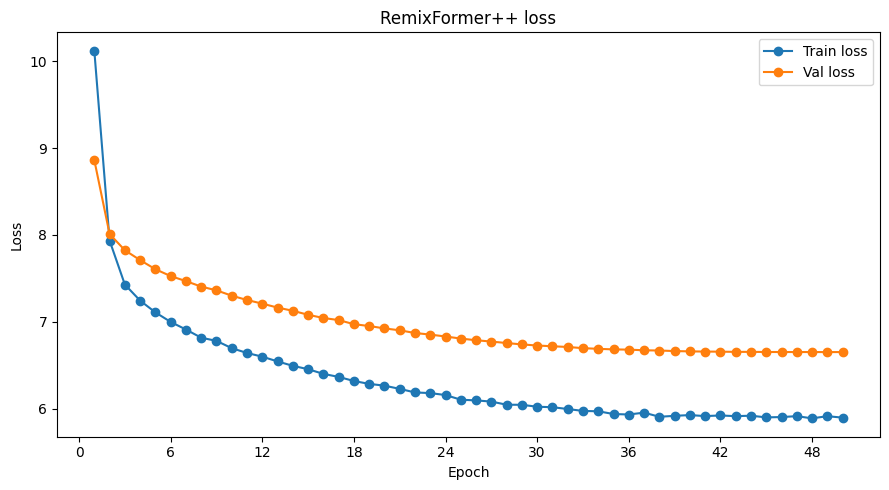

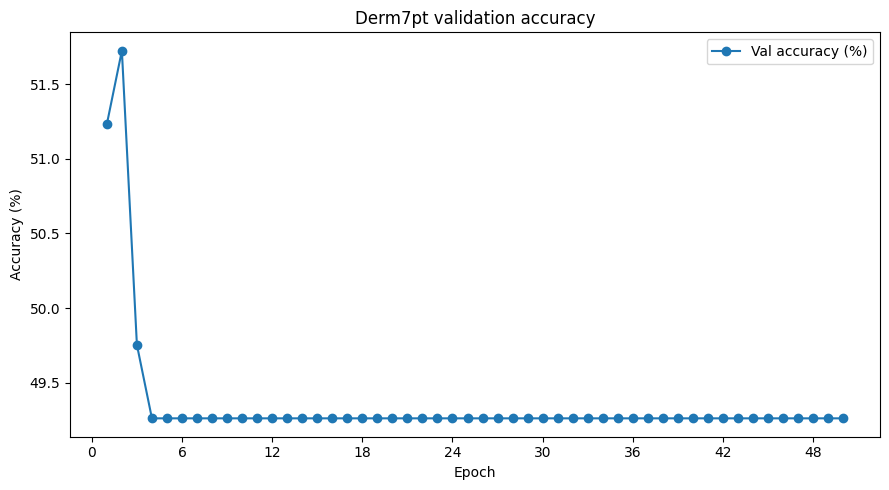

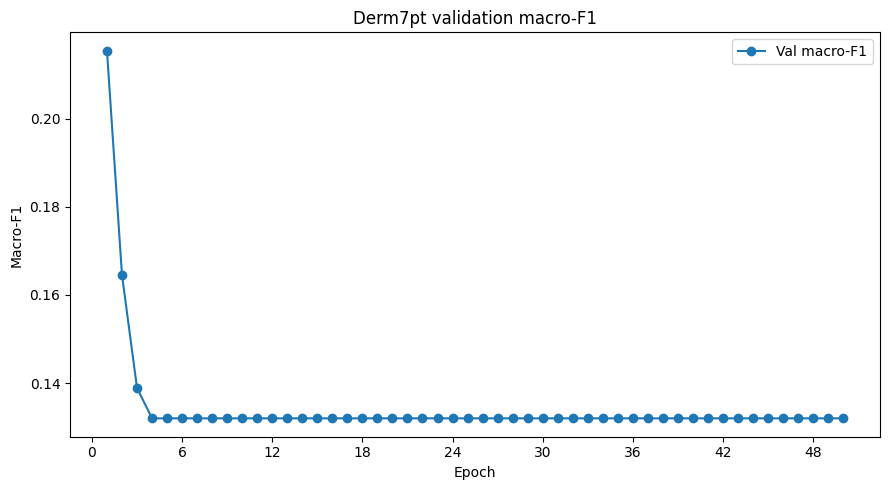

In [23]:
# 23. Training curves
from matplotlib.ticker import MaxNLocator

h = pd.DataFrame(history)
fig,ax=plt.subplots(figsize=(9,5))
ax.plot(h["epoch"],h["train_loss"],marker="o",label="Train loss")
ax.plot(h["epoch"],h["val_loss"],marker="o",label="Val loss")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_title("RemixFormer++ loss")
ax.legend(); fig.tight_layout(); fig.savefig(PLOT_DIR/"loss.png",dpi=180); plt.show()

fig,ax=plt.subplots(figsize=(9,5))
ax.plot(h["epoch"],h["val_acc"]*100,marker="o",label="Val accuracy (%)")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy (%)"); ax.set_title("Derm7pt validation accuracy")
ax.legend(); fig.tight_layout(); fig.savefig(PLOT_DIR/"val_accuracy.png",dpi=180); plt.show()

fig,ax=plt.subplots(figsize=(9,5))
ax.plot(h["epoch"],h["val_macro_f1"],marker="o",label="Val macro-F1")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Epoch"); ax.set_ylabel("Macro-F1"); ax.set_title("Derm7pt validation macro-F1")
ax.legend(); fig.tight_layout(); fig.savefig(PLOT_DIR/"val_f1.png",dpi=180); plt.show()


=== BEST CHECKPOINT TEST RESULTS ===
Accuracy: 56.20%
Macro-F1: 0.2422
Balanced Accuracy: 0.2614
Macro Precision: 0.2256
Macro Recall: 0.2614
OVR AUC: nan

Classification report:
              precision    recall  f1-score   support

         BCC       0.00      0.00      0.00        16
         Nev       0.65      0.76      0.70       219
         Mel       0.48      0.54      0.51       101
          SK       0.00      0.00      0.00        19
        Misc       0.00      0.00      0.00        40

    accuracy                           0.56       395
   macro avg       0.23      0.26      0.24       395
weighted avg       0.48      0.56      0.52       395



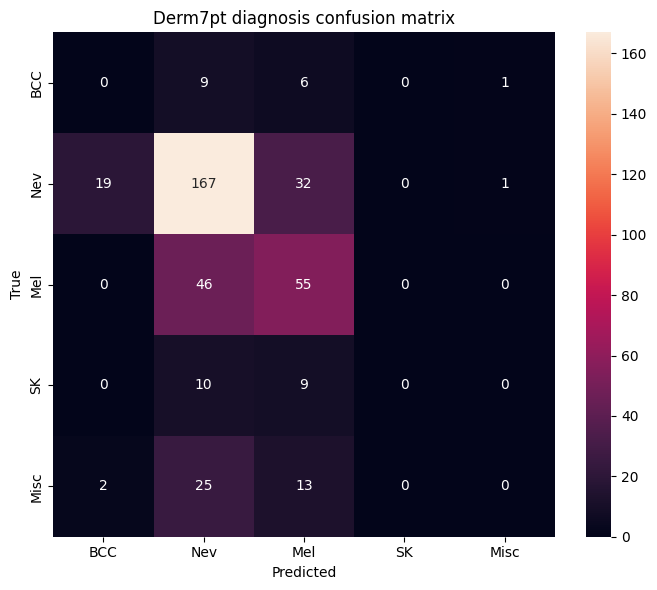

In [24]:
# 24. Best-checkpoint test evaluation
best_path = CKPT_DIR/"best.pth"
if not best_path.exists():
    raise FileNotFoundError("best.pth was not created.")

best_ckpt = torch.load(best_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(best_ckpt["model_state_dict"], strict=True)

test_metrics, y_true, y_prob = evaluate(test_loader)
y_pred = y_prob.argmax(axis=1)

print("=== BEST CHECKPOINT TEST RESULTS ===")
print(f"Accuracy: {test_metrics['acc']*100:.2f}%")
print(f"Macro-F1: {test_metrics['macro_f1']:.4f}")
print(f"Balanced Accuracy: {test_metrics['bal_acc']:.4f}")
print(f"Macro Precision: {test_metrics['precision_macro']:.4f}")
print(f"Macro Recall: {test_metrics['recall_macro']:.4f}")
print(f"OVR AUC: {test_metrics['auc_ovr']:.4f}")

print("\nClassification report:")
print(classification_report(y_true,y_pred,target_names=DIAG_NAMES,zero_division=0))

cm = confusion_matrix(y_true,y_pred,labels=list(range(NUM_DIAG_CLASSES)))
fig,ax=plt.subplots(figsize=(7,6))
sns.heatmap(cm,annot=True,fmt="d",xticklabels=DIAG_NAMES,yticklabels=DIAG_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Derm7pt diagnosis confusion matrix")
fig.tight_layout(); fig.savefig(PLOT_DIR/"test_confusion_matrix.png",dpi=180); plt.show()


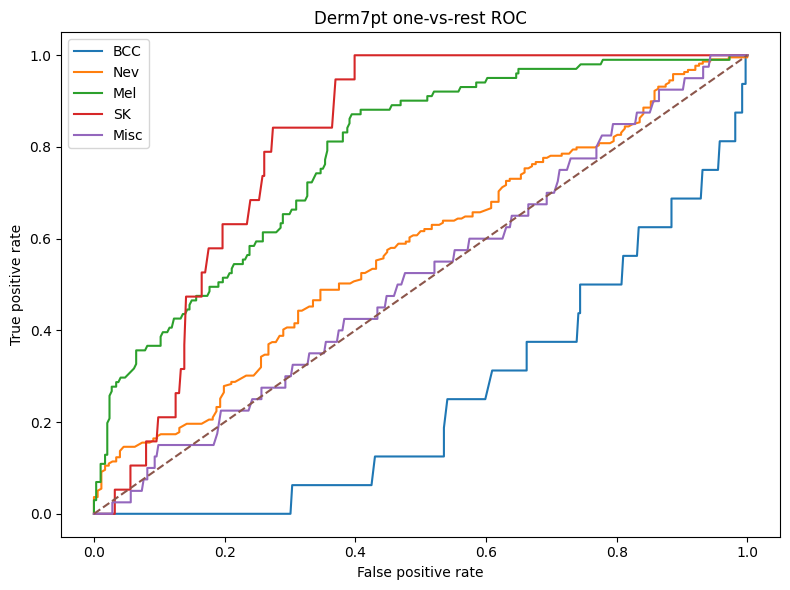

In [25]:
# 25. ROC / PR curves
try:
    from sklearn.preprocessing import label_binarize
    y_bin = label_binarize(y_true, classes=list(range(NUM_DIAG_CLASSES)))
    fig,ax=plt.subplots(figsize=(8,6))
    for k,name in enumerate(DIAG_NAMES):
        fpr,tpr,_=roc_curve(y_bin[:,k],y_prob[:,k])
        ax.plot(fpr,tpr,label=name)
    ax.plot([0,1],[0,1],"--")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title("Derm7pt one-vs-rest ROC")
    ax.legend(); fig.tight_layout(); fig.savefig(PLOT_DIR/"roc_ovr.png",dpi=180); plt.show()
except Exception as e:
    print("ROC plot skipped:",e)


In [26]:
# 26. Final intermediate visualization from the BEST trained model

if LSM_VISUALIZE_ONLY_AFTER_TRAINING:
    best_path = CKPT_DIR / "best.pth"
    if not best_path.exists():
        raise FileNotFoundError("Best checkpoint not found. Training must finish first.")

    best_ckpt = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(best_ckpt["model_state_dict"], strict=True)
    model.eval()

    final_audit_dir = save_intermediate_audit(
        test_ds,
        sample_index=VIS_SAMPLE_INDEX,
        tag="final_best_test_sample"
    )
    print("Final trained LSM/HRWE audit:", final_audit_dir)
    print("The K=4 boxes above are now generated from the restored best trained model.")
else:
    print("Final LSM visualization disabled.")


Saved intermediate audit: /kaggle/working/remixformerpp_full_verified/intermediates/final_best_test_sample_sample_0000
  LSM K=4 indices: [53, 99, 52, 77]
  LSM K=4 centers (x,y): [[410.6700134277344, 336.0], [261.3299865722656, 634.6699829101562], [336.0, 336.0], [410.6700134277344, 485.3299865722656]]
  Diagnosis probabilities: [0.1492999941110611, 0.23520000278949738, 0.24629999697208405, 0.1550000011920929, 0.2142000049352646]
Final trained LSM/HRWE audit: /kaggle/working/remixformerpp_full_verified/intermediates/final_best_test_sample_sample_0000
The K=4 boxes above are now generated from the restored best trained model.


In [27]:
# 27. Save final model, configuration, transfer audit and report
model_only_path = OUTPUT_ROOT/"RemixFormerPP_FULL_best_model.pth"
torch.save({
    "model_state_dict": model.state_dict(),
    "meta_dim": META_DIM,
    "checklist_specs": CHECKLIST_SPECS,
    "diagnosis_names": DIAG_NAMES,
    "config": {
        "clinical_size": CLINICAL_SIZE,
        "global_clinical_size": GLOBAL_CLINICAL_SIZE,
        "local_patch_size": LOCAL_PATCH_SIZE,
        "dermoscopy_size": DERMOSCOPY_SIZE,
        "derm_window_size": DERM_WINDOW_SIZE,
        "num_derm_windows": NUM_DERM_WINDOWS,
        "lsm_k": LSM_K,
        "vit_dim": VIT_DIM,
        "vit_depth": VIT_DEPTH,
        "vit_heads": VIT_HEADS,
        "msta_templates": MSTA_TEMPLATES,
        "paper_mode": PAPER_MODE,
        "lsm_sampling": "differentiable attention sampling during training; deterministic top-K during evaluation",
        "lsm_crop_size": LOCAL_PATCH_SIZE,
    },
    "transfer_audit": audit,
}, model_only_path)

report = {
    "dataset": "Derm7pt",
    "official_split": {"train":413,"val":203,"test":395},
    "architecture": {
        "clinical":"896 -> 384 global -> CLS_WMSA Swin-T -> LSM K=4 -> 224 crops -> local modified Swin -> CSF",
        "dermoscopy":"1024 -> 16x256 -> ViT-S/16 384-D 12-layer 6-head -> MSTA K=32 -> 17-token 12-layer 6-head region encoder",
        "metadata":"one-hot -> Linear -> BatchNorm -> ReLU -> 768",
        "cmf":"cyclic 8-head cross-modality fusion",
        "diagnosis_classes":5,
        "checklist_heads":7
    },
    "best_epoch": best_epoch,
    "best_validation_macro_f1": BEST_F1,
    "test_metrics": {k: float(v) for k,v in test_metrics.items()},
    "transfer_audit": audit,
    "intermediate_root": str(INTERMEDIATE_DIR),
    "best_checkpoint": str(CKPT_DIR/"best.pth"),
    "last_checkpoint": str(CKPT_DIR/"last.pth"),
    "model_only_checkpoint": str(model_only_path),
    "note": "Paper-aligned reimplementation. Exact author source/checkpoints are not publicly supplied. Final LSM visualization is generated only after best-checkpoint restoration."
}
(REPORT_DIR/"final_report.json").write_text(json.dumps(report,indent=2,default=str))
(OUTPUT_ROOT/"config.json").write_text(json.dumps({
    "epochs":EPOCHS_THIS_RUN,
    "batch_size":BATCH_SIZE,
    "grad_accum":GRAD_ACCUM_STEPS,
    "lr":LR,
    "paper_mode":PAPER_MODE,
    "architecture":report["architecture"],
    "transfer_audit":audit,
},indent=2,default=str))

print("Saved:", model_only_path)
print("Best:", CKPT_DIR/"best.pth")
print("Last:", CKPT_DIR/"last.pth")
print("Intermediate artifacts:", INTERMEDIATE_DIR)
print("Final report:", REPORT_DIR/"final_report.json")


Saved: /kaggle/working/remixformerpp_full_verified/RemixFormerPP_FULL_best_model.pth
Best: /kaggle/working/remixformerpp_full_verified/checkpoints/best.pth
Last: /kaggle/working/remixformerpp_full_verified/checkpoints/last.pth
Intermediate artifacts: /kaggle/working/remixformerpp_full_verified/intermediates
Final report: /kaggle/working/remixformerpp_full_verified/reports/final_report.json
